# <font color = "red">**Deciphering the Decision Logic of an AI Agent**</font>

- Can we infer what an AI agent values by observing the sequence of decisions it makes?

- In this challenge, GPT acts as an autonomous microscopy agent that repeatedly selects one measurement location from a set of candidate AFM image patches.

- We record its decisions and then attempt to reverse-engineer the hidden logic behind those choices using visual, statistical, and data-driven methods.

<font color = "blue" size = 6>**Goal**</font>: develop a method that best explains GPT’s behavior and predicts its future decisions on unseen candidate sets.

<a href="https://colab.research.google.com/github/kbarakati/camm_hackathon/blob/k4my4r/docs/day_20_10092026/llm_decision_making.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports and reproducibility

In [ ]:
! pip install -q igor2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from igor2 import binarywave
import pickle

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

import random
np.random.seed(42)
import glob
import pickle


Download data

In [ ]:
! gdown --folder "https://drive.google.com/drive/folders/1qN-AdhA19oHG3yNo7te7stjzQ_VM1OY_?usp=sharing"

# Local

In [2]:
import pickle
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fixed random seed, so every run gives the same random numbers
np.random.seed(42)
random.seed(42)

# All data files sit directly in the day 23 folder, next to the notebook
DATA_DIR = Path("/Users/borisslautin/Documents/GitHub/athena_camm_hackathon/docs/day_23_10232026")

In [3]:
fname = DATA_DIR / "Plasmonic_sets_hackathon.npy"

raw = np.load(fname, allow_pickle=True)
loadedfile = raw.tolist()          # turn the numpy object into a normal Python dict

print("Available datasets:", loadedfile.keys())

Available datasets: dict_keys(['0', '1', '2', '3'])


In [4]:
# All 5 traces were recorded on dataset "0" (I checked: their spectra match this dataset pixel by pixel)
data = loadedfile["0"]

image   = data["image"]            # structural image, shape (66, 152)
spectra = data["spectrum image"]   # one EELS spectrum per pixel, shape (66, 152, 4198)
energy  = data["energy axis"]      # energy in eV, shape (4198,)

H, W, N_E = spectra.shape

print("Image:", image.shape)
print("Spectral image:", spectra.shape)
print("Energy axis:", energy.shape)

Image: (66, 152)
Spectral image: (66, 152, 4198)
Energy axis: (4198,)


In [5]:
# Same order as the original notebook, so TRACE_ID = 4 is still P03
trace_files = [
    DATA_DIR / "eels_ei_trace.pkl",
    DATA_DIR / "eels_random_trace.pkl",
    DATA_DIR / "eels_ucb_trace.pkl",
    DATA_DIR / "trace_P01_eels_.pkl",
    DATA_DIR / "trace_P03_eels.pkl",
]


class NoTorchUnpickler(pickle.Unpickler):
    """Backup loader for when torch is not installed.
    The EI / random / UCB files keep the saved model weights as torch tensors.
    This loader puts None in place of those tensors. The decisions are not affected."""
    def find_class(self, module, name):
        if module.startswith("torch"):
            return lambda *args, **kwargs: None
        return super().find_class(module, name)


def load_trace(path):
    with open(path, "rb") as f:
        try:
            return pickle.load(f)                  # normal way (needs torch for the EI/random/UCB files)
        except ModuleNotFoundError:
            f.seek(0)                              # go back to the start of the file
            return NoTorchUnpickler(f).load()      # backup way, without torch


traces = {}
for i, f in enumerate(trace_files):
    traces[i] = load_trace(f)
    print(f"Trace {i}: {f.name}  ->  {len(traces[i]['decisions'])} steps")

Trace 0: eels_ei_trace.pkl  ->  200 steps
Trace 1: eels_random_trace.pkl  ->  200 steps
Trace 2: eels_ucb_trace.pkl  ->  200 steps
Trace 3: trace_P01_eels_.pkl  ->  100 steps
Trace 4: trace_P03_eels.pkl  ->  100 steps


In [6]:
# For every trace, test that the saved spectrum equals the spectrum at the same pixel of dataset "0"
for i, tr in traces.items():
    d = tr["decisions"][0]
    y, x = d["selected_coordinates"]
    same_spectrum = np.allclose(spectra[y, x], d["selected_spectrum"])
    same_index = d["selected_index"] == y * W + x      # flat pixel number = row * W + column
    print(f"Trace {i}: spectrum match = {same_spectrum}, index match = {same_index}")

Trace 0: spectrum match = True, index match = True
Trace 1: spectrum match = True, index match = True
Trace 2: spectrum match = True, index match = True
Trace 3: spectrum match = True, index match = True
Trace 4: spectrum match = True, index match = True


## load data

In [ ]:
fname = "/content/Plasmonic_sets_hackathon.npy"

raw = np.load(fname, allow_pickle=True)
loadedfile = raw.tolist()

print("Available datasets:", loadedfile.keys())

Available datasets: dict_keys(['0', '1', '2', '3'])


In [ ]:
# Use the same dataset as the previous challenge
data = loadedfile["0"]

image = data["image"]
spectra = data["spectrum image"]
energy = data["energy axis"]

H, W, N_E = spectra.shape

print("Image:", image.shape)
print("Spectral image:", spectra.shape)
print("Energy axis:", energy.shape)

Image: (66, 152)
Spectral image: (66, 152, 4198)
Energy axis: (4198,)


# Genetic algorithm

# Reverse-engineering the decision rule of a measurement agent

## 1. The method

**Question.** An agent (a BO algorithm, a human, or a random picker) explores an EELS spectrum image.
At every step it sees 20 candidate locations (as 16×16 image patches), picks one, and the
spectrum at that point is revealed. We only see the image, the candidates, the choices and the
revealed spectra. We want to find out **what rule the agent follows**.

**Idea.** Every guess of the rule is written as a short list of *descriptors* (numbers that
describe each candidate). A candidate's score is a weighted sum of its descriptors:

    score = w1·descriptor1 + w2·descriptor2 + ...
    P(candidate is chosen) = exp(score) / sum of exp(score) over the 20 candidates   (softmax)

A good guess gives a high probability to the candidates the agent really picked.

**Steps.**
1. **Bank of descriptors.** We compute many descriptors for every candidate at every step:
   image, position, history and spectral (listed below). Near-copies (rank correlation > 0.95)
   are merged, so each idea appears only once.
2. **Respect what the agent knew.** At step *t* the agent knows the image and the spectra
   measured *before* *t*, nothing else. Image and position descriptors are used directly.
   Spectral descriptors are used only through the history (see "μ, σ, best, stay" below),
   because the spectrum of a candidate is unknown before measuring it.
3. **Fitness (the score of a guess).** For a given list of descriptors, the weights are fitted
   exactly (convex softmax fit). The guess is then tested on **blocks of steps it was not
   fitted on** (5 time blocks, each predicted once):

       explained = 1 − log P(real choices) / log P(random guessing)
       fitness   = explained − 0.005 × (number of descriptors)

   0 = no better than random, 1 = every choice predicted. The small cost per descriptor
   makes simple explanations win.
4. **Genetic algorithm (GA).** A population of 60 random guesses (1–5 descriptors each) evolves:
   the 6 best are kept, parents are chosen by tournament (best of 3), children mix their
   parents' descriptors (crossover) and get one small random change (mutation: add, remove or
   swap a descriptor). It stops when the best fitness has not improved for 10 generations.
   New descriptors are proposed family-first, so that big families do not dominate by number.
5. **Checks.**
   - *Planted agents:* a rule we invent must be found again, with the right weights.
   - *Random trace:* must give "no rule" (fitness ≈ 0).
   - *Shuffled spectra:* if an agent really uses the spectra, shuffling them must lower the
     fitness; we accept a spectral descriptor only if it beats the shuffled version.
   - *Several GA runs:* the core of the answer must be the same with different seeds.

**Output.** For each agent: the descriptors it follows, their weights (+ = seeks, − = avoids),
how often its real choice is predicted (exact and top 3), and a map of its preferences over the image.

---

## 2. The descriptors

All descriptors are computed **per candidate**. Before fitting, each one is centred within each
step (only differences between the 20 candidates matter) and scaled to a common size.

### 2.1 Image descriptors: what the 16×16 patch looks like
The agent sees these directly.

| Descriptor | What it measures | Simple meaning |
|---|---|---|
| `img_mean` | average brightness of the patch (also stands for p10, p90 and PCA 1) | bright vs dark region |
| `img_std` | spread of brightness | contrast: flat area vs mixed area |
| `img_min`, `img_max` | darkest / brightest pixel | contains very dark / very bright spots |
| `img_center` | brightness of the central 4×4 pixels (the measured point) | is the point itself bright? |
| `img_center_minus_mean` | centre minus patch average | is the point brighter than its surroundings (on a particle) or darker? |
| `img_grad_mean` | average edge strength (size of the brightness gradient) | how many edges / borders |
| `img_grad_max` | strongest edge | contains one sharp border |
| `img_laplacian` | average size of the Laplacian (local curvature) | small sharp details, spots, corners |
| `img_particle_fraction` | share of pixels brighter than the Otsu threshold (automatic particle/background level) | how much of the patch is particle |
| `img_edge_fraction` | share of pixels with very strong edges (top 10% of the image) | how much particle border is in the patch |
| `img_anisotropy` | 0 = edges in all directions, 1 = edges all in one direction | elongated / striped vs round structure |
| `img_pca2` … `img_pca6` | amount of each main "shape" learned from all patches by PCA | typical structural patterns of this image |

### 2.2 Position descriptors: where the candidate is
| Descriptor | Simple meaning |
|---|---|
| `pos_row` | 0 = top of the image, 1 = bottom |
| `pos_col` | 0 = left, 1 = right |
| `pos_dist_border` | distance to the nearest image edge |
| `pos_dist_center` | distance to the image centre |

### 2.3 History descriptors: the candidate compared with what was already measured
They change at every step, because the history grows.

| Descriptor | Simple meaning |
|---|---|
| `hist_dist_last` | distance (in pixels) to the last measured point: short step vs big jump |
| `hist_dist_nearest` | distance to the nearest measured point: filling gaps / covering the image |
| `hist_crowd` | number of measured points within 8 pixels: staying in a busy area vs avoiding it |
| `hist_same_direction` | +1 = continues in the direction of the last move, −1 = goes back: scanning in lines |
| `hist_novelty` | how different the patch looks from the 5 most similar measured patches: exploring new structures |
| `hist_sim_last` | how similar the patch looks to the last measured patch: "more of the same" |
| `hist_time` | step number / total steps: lets a rule change between early and late steps |

### 2.4 Spectral rewards: possible goals the agent might chase
A spectral reward *g* turns one spectrum into one number. We use 69 of them.

| Reward | What it measures |
|---|---|
| `spec_total_mean` | mean intensity of the whole spectrum (the true DKL reward; also stands for peak height, the 0.4–0.6 eV bands and spectral PCA 1) |
| `spec_peak_energy` | energy of the main plasmon peak (searched in 0.25–1.0 eV, after smoothing) |
| `spec_peak_width` | width of that peak at half its height |
| `spec_centroid` | "centre of mass" of the spectrum in 0.25–1.0 eV (also stands for high-vs-low energy balance) |
| `spec_band_E1_E2` | mean intensity in fixed bands: 0.2–0.3, 0.3–0.4, 0.6–0.7, 0.7–0.8, 0.8–1.0, 1.0–1.5, 1.5–2.3 eV |
| `spec_pca2` … `spec_pca4` | amount of each main spectral shape (after the overall intensity) |
| `win_E1_E2` | mean intensity in any window between the edges 0.2, 0.3, …, 1.0, 1.5, 2.3 eV (55 windows) |

### 2.5 How spectral rewards become descriptors (using only the history)
The agent cannot see a candidate's spectrum before measuring it. It can only guess from the
patches it has already measured. So every reward *g* enters through the history:

| Descriptor | Simple meaning |
|---|---|
| `mu(g, mem=m)` | **the predicted reward of the candidate**: a Gaussian-process guess of *g* from how much the candidate's patch looks like measured patches (patches described by the image descriptors). `mem` = how many past steps count: old points are down-weighted by exp(−age/m); m = 1, 3, 10, 30 or all. 69 rewards × 5 memories = 345 descriptors. |
| `sigma(mem=m)` | **how unsure that guess is**: large when the patch looks like nothing measured so far. Seeking high σ = exploring. Same for every reward. |
| `best(g)` | how similar the candidate looks to **the best patch measured so far** (best = highest *g*): going back to what worked |
| `stay_if_good(g)` | (was the last result good?) × (does the candidate look like the last patch?): "stay if good, move away if bad" |

In total the bank has **516 descriptors**: 17 image, 4 position, 7 history, 5 σ and 483 spectral (μ, best, stay).

In [7]:
# ============================================================
# STEP 1 — CUT A 16x16 PATCH AROUND EVERY PIXEL OF THE IMAGE
# ============================================================
# Why: later we describe every possible location by numbers
# (brightness, edges, ...). For that we need the patch the agent
# would have seen at that location.
#
# How the agents cut a patch (checked on the traces):
#   patch = image[y-8 : y+8, x-8 : x+8]
#   near the image border the image is mirrored to fill the patch

PATCH = 16              # patch size used by all agents
HALF = PATCH // 2       # 8 pixels on each side

# Mirror the image by 8 pixels on every side, so border patches are complete
padded = np.pad(image, HALF, mode="reflect")

# Take a 16x16 window starting at every pixel of the padded image.
# Window (y, x) of the padded image = patch centred at pixel (y, x) of the original image.
all_patches = np.lib.stride_tricks.sliding_window_view(padded, (PATCH, PATCH))[:H, :W]

# Make it a simple list of patches: patch number = y * W + x
# (the same numbering as "selected_index" / "candidate_indices" in the traces)
all_patches = all_patches.reshape(H * W, PATCH, PATCH).astype(np.float32)

print("All patches:", all_patches.shape)    # expected: (10032, 16, 16)


# ------------------------------------------------------------
# CHECK: are our patches the same as the ones stored in the traces?
# ------------------------------------------------------------
# The DKL traces store patches after rescaling (z-score of the image),
# the human traces store raw values. So we compare the PATTERN
# (correlation), not the raw numbers. 1.0 = identical pattern.

def same_pattern(a, b):
    a = a.ravel() - a.mean()
    b = b.ravel() - b.mean()
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)

for tid, tr in traces.items():
    worst = 1.0
    for d in tr["decisions"]:
        for patch, idx in zip(d["candidate_patches"], d["candidate_indices"]):
            worst = min(worst, same_pattern(np.squeeze(patch), all_patches[int(idx)]))
    status = "OK" if worst > 0.999 else "PROBLEM"
    print(f"Trace {tid}: worst match = {worst:.6f}  ->  {status}")

All patches: (10032, 16, 16)
Trace 0: worst match = 1.000000  ->  OK
Trace 1: worst match = 1.000000  ->  OK
Trace 2: worst match = 1.000000  ->  OK
Trace 3: worst match = 1.000000  ->  OK
Trace 4: worst match = 1.000000  ->  OK


Image terms: (10032, 20)
Missing values: 0
Particle level = 0.144  (particle covers 29% of the image)


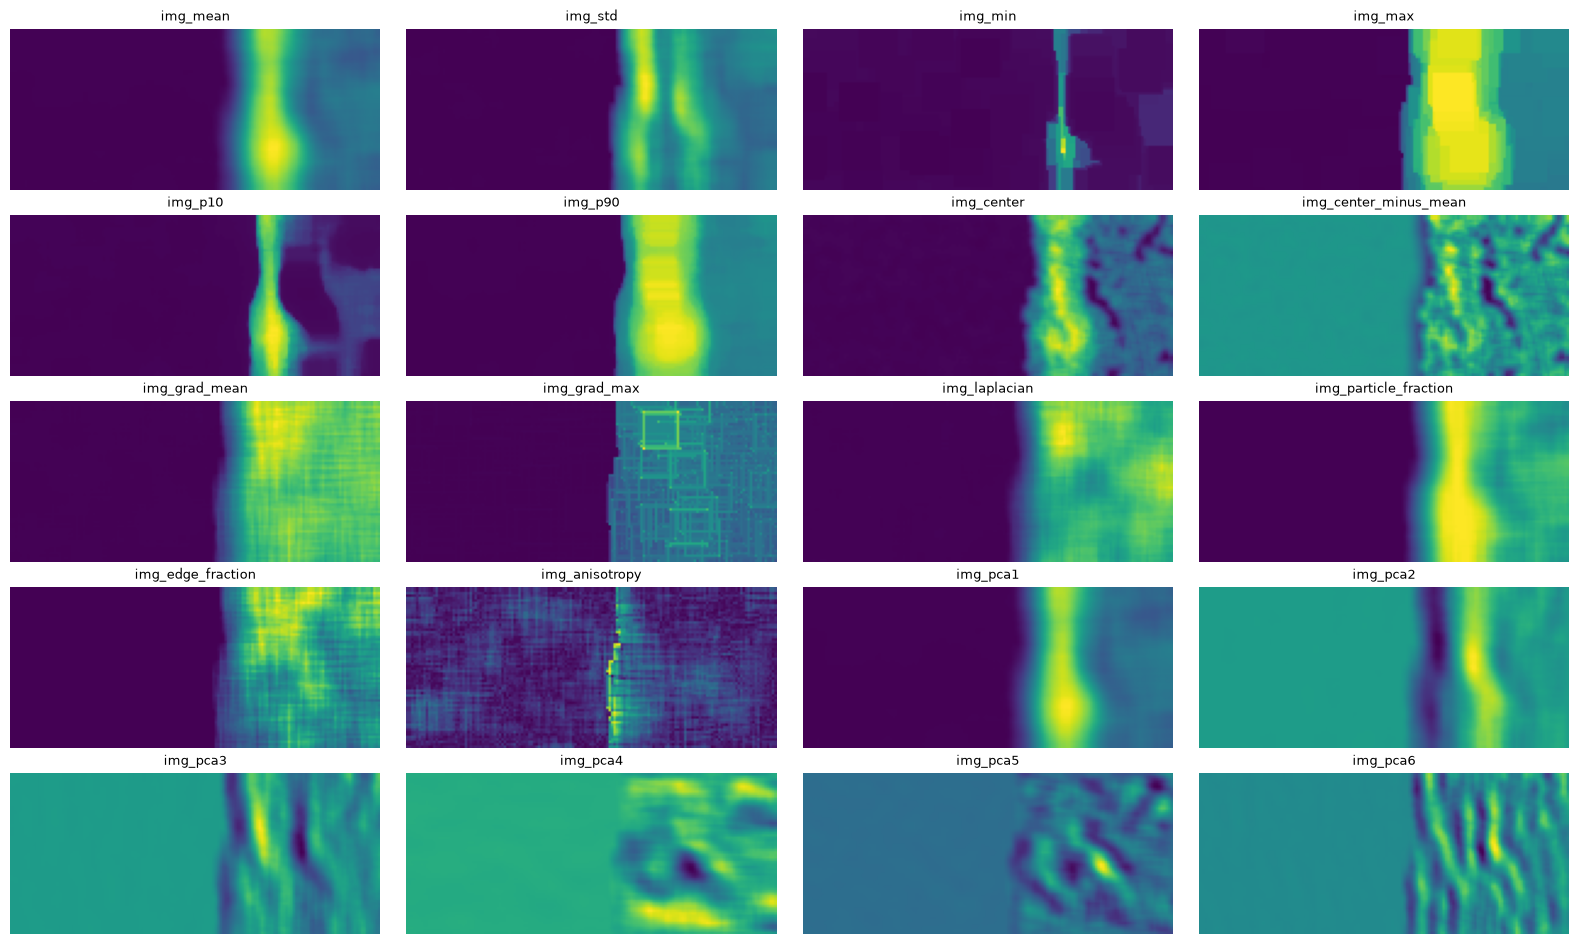

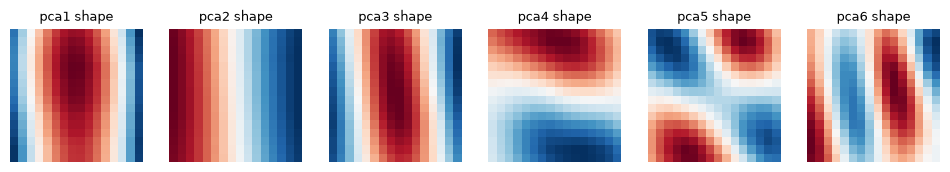

In [8]:
# ============================================================
# STEP 2 — THE BANK OF IMAGE TERMS
# ============================================================
# For every patch we compute simple numbers that describe what it
# looks like. Each number is one possible thing an agent might "like".
# Result: a table "image_terms", one row per pixel (row number = y * W + x),
# one column per term.

P = all_patches.astype(np.float64)     # (N, 16, 16)
N = len(P)
flat = P.reshape(N, -1)                # each patch as one row of 256 values

# --- helpers: gradient (edges) and Laplacian (sharp spots / curvature) ---
gy, gx = np.gradient(P, axis=(1, 2))                 # change along y and x
grad = np.sqrt(gx**2 + gy**2)                        # edge strength per pixel
lap = (np.roll(P, 1, 1) + np.roll(P, -1, 1)
       + np.roll(P, 1, 2) + np.roll(P, -1, 2) - 4 * P)[:, 1:-1, 1:-1]   # drop the border (roll wraps around)


# --- helper: Otsu threshold = the brightness level that best splits the image
#     into "particle" and "background" (picked automatically from the histogram)
def otsu_threshold(values, n_bins=256):
    hist, edges = np.histogram(values, bins=n_bins)
    centers = (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(hist)                     # pixels below each level
    w1 = w0[-1] - w0                         # pixels above each level
    m0 = np.cumsum(hist * centers) / np.maximum(w0, 1)                              # mean below
    m1 = (np.sum(hist * centers) - np.cumsum(hist * centers)) / np.maximum(w1, 1)   # mean above
    return centers[np.argmax(w0 * w1 * (m0 - m1) ** 2)]   # level with the best separation

particle_level = otsu_threshold(image.ravel())   # one level for the whole image
edge_level = np.percentile(grad, 90)             # "strong edge" = top 10% of edge strength

# --- centre of the patch (4x4 pixels around the measured point) ---
c = slice(HALF - 2, HALF + 2)
center = P[:, c, c].mean(axis=(1, 2))

# --- anisotropy: 0 = no preferred direction, 1 = all edges point the same way ---
Jxx = (gx * gx).mean(axis=(1, 2))
Jyy = (gy * gy).mean(axis=(1, 2))
Jxy = (gx * gy).mean(axis=(1, 2))
anisotropy = np.sqrt((Jxx - Jyy) ** 2 + 4 * Jxy ** 2) / (Jxx + Jyy + 1e-12)

# --- the table of terms ---
image_terms = pd.DataFrame({
    # brightness and contrast
    "img_mean":   flat.mean(1),
    "img_std":    flat.std(1),
    "img_min":    flat.min(1),
    "img_max":    flat.max(1),
    "img_p10":    np.percentile(flat, 10, axis=1),
    "img_p90":    np.percentile(flat, 90, axis=1),
    # the measured point itself, and whether it is brighter than its surroundings
    "img_center":            center,
    "img_center_minus_mean": center - flat.mean(1),
    # edges and sharp features
    "img_grad_mean": grad.mean(axis=(1, 2)),
    "img_grad_max":  grad.max(axis=(1, 2)),
    "img_laplacian": np.abs(lap).mean(axis=(1, 2)),
    # shape
    "img_particle_fraction": (flat > particle_level).mean(1),             # share of particle pixels
    "img_edge_fraction":     (grad.reshape(N, -1) > edge_level).mean(1),  # share of strong-edge pixels
    "img_anisotropy":        anisotropy,
})

# --- PCA: the main "shapes" that patches vary by, learned from the image itself ---
N_PCA = 6
centered = flat - flat.mean(0)
_, _, Vt = np.linalg.svd(centered, full_matrices=False)    # rows of Vt = the main shapes
pcs = centered @ Vt[:N_PCA].T                               # how much of each shape is in each patch
for k in range(N_PCA):
    image_terms[f"img_pca{k + 1}"] = pcs[:, k]

print("Image terms:", image_terms.shape)                           # expected: (10032, 20)
print("Missing values:", int(image_terms.isna().sum().sum()))      # expected: 0
print(f"Particle level = {particle_level:.3f}  (particle covers {(image > particle_level).mean():.0%} of the image)")


# ------------------------------------------------------------
# CHECK: paint every term over the image
# ------------------------------------------------------------
# Each panel = one term, value at every pixel. They should look like
# sensible "maps" of the structure (bright particles, edges, ...).

cols = image_terms.columns
ncols = 4
nrows = int(np.ceil(len(cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 1.9 * nrows))
for ax, name in zip(axes.ravel(), cols):
    ax.imshow(image_terms[name].values.reshape(H, W), cmap="viridis")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Show the 6 PCA shapes themselves (what each img_pca component means)
fig, axes = plt.subplots(1, N_PCA, figsize=(2 * N_PCA, 2))
for k, ax in enumerate(axes):
    ax.imshow(Vt[k].reshape(PATCH, PATCH), cmap="RdBu_r")
    ax.set_title(f"pca{k + 1} shape", fontsize=9)
    ax.axis("off")
plt.show()

Spectral terms: (10032, 19)
Missing values: 0
Variance explained by spectral PCA: [0.928 0.045 0.012 0.004]
Matches DKL reward: True
Position terms: (10032, 4)


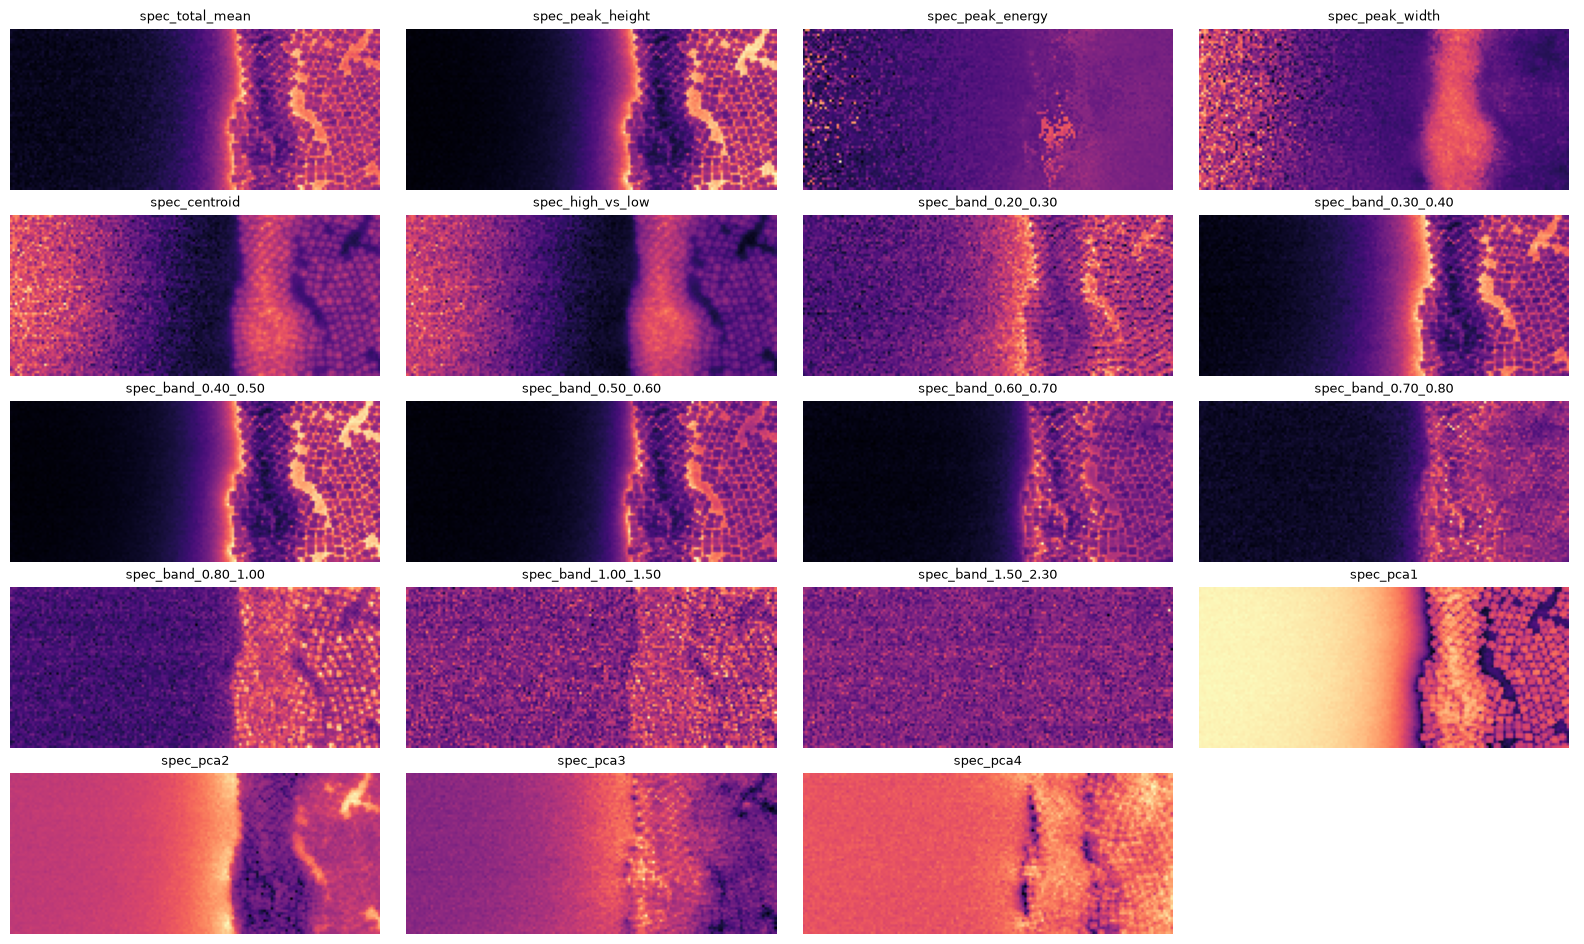

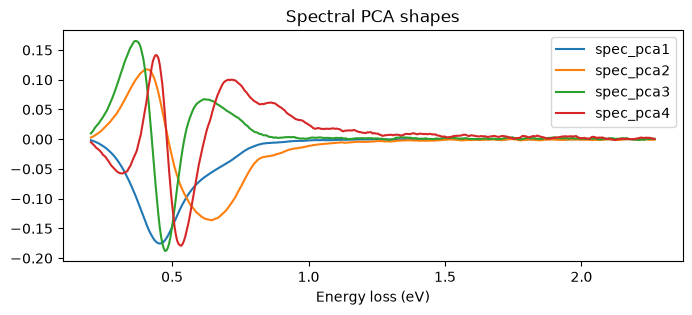

In [9]:
# ============================================================
# STEP 3A — THE BANK OF SPECTRAL TERMS
# ============================================================
# For every pixel we turn its spectrum into simple numbers.
# Each number is one possible "reward" an agent might be chasing.
#
# IMPORTANT: the agent only knows these numbers for points it has
# ALREADY MEASURED. We compute them for all pixels here only for
# convenience; step 5 will read them for the history only.

energy = data["energy axis"]

# --- 1. Bin the spectra: average every 10 energy points ---
# 4198 points -> 419 bins of ~0.005 eV. Less noise, 10x less memory, nothing physical lost.
BIN = 10
n_keep = (N_E // BIN) * BIN                         # drop the last few points so it divides evenly
spec = spectra.reshape(H * W, N_E)[:, :n_keep].reshape(H * W, -1, BIN).mean(-1)   # (N, 419)
E = energy[:n_keep].reshape(-1, BIN).mean(-1)                                      # (419,)
dE = E[1] - E[0]

# --- 2. Fast mean in ANY energy window [E1, E2] (the GA will use this later) ---
# Trick: with a running sum, the sum over a window = sum up to E2 minus sum up to E1.
spec_cumsum = np.concatenate([np.zeros((len(spec), 1)), np.cumsum(spec, axis=1)], axis=1)

def window_mean(E1, E2):
    """Mean intensity between E1 and E2 (eV), for every pixel at once."""
    i1 = int(np.searchsorted(E, min(E1, E2)))
    i2 = int(np.searchsorted(E, max(E1, E2)))
    i2 = min(max(i2, i1 + 1), len(E))      # at least one bin, never past the end
    i1 = min(i1, i2 - 1)
    return (spec_cumsum[:, i2] - spec_cumsum[:, i1]) / (i2 - i1)

# --- 3. Smooth the spectra a bit more, only for the peak terms (spectra are noisy) ---
SMOOTH = 9                                  # 9 bins ~ 0.045 eV
kernel = np.ones(SMOOTH) / SMOOTH
smooth = np.apply_along_axis(lambda s: np.convolve(s, kernel, mode="same"), 1, spec)

# --- 4. Plasmon peak terms, searched where the peaks are (0.25 - 1.0 eV) ---
PEAK_RANGE = (0.25, 1.0)
in_range = (E >= PEAK_RANGE[0]) & (E <= PEAK_RANGE[1])
E_r = E[in_range]
S_r = smooth[:, in_range]

peak_i = np.argmax(S_r, axis=1)                                  # where the highest point is
peak_height = S_r[np.arange(len(S_r)), peak_i]                   # how high it is
peak_energy = E_r[peak_i]                                        # at which energy
peak_width = (S_r > peak_height[:, None] / 2).sum(1) * dE        # width at half height (approx.)

weights = np.clip(S_r, 0, None)                                  # ignore negative noise
centroid = (weights * E_r).sum(1) / (weights.sum(1) + 1e-12)     # "centre of mass" of the spectrum

# shape: is the intensity more at high or low energy? (-1 = all low, +1 = all high)
low = window_mean(0.25, 0.55)
high = window_mean(0.55, 1.00)
high_vs_low = (high - low) / (np.abs(high) + np.abs(low) + 1e-12)

spectral_terms = pd.DataFrame({
    "spec_total_mean":  spectra.reshape(H * W, N_E).mean(1),    # = the DKL reward
    "spec_peak_height": peak_height,
    "spec_peak_energy": peak_energy,
    "spec_peak_width":  peak_width,
    "spec_centroid":    centroid,
    "spec_high_vs_low": high_vs_low,
})

# --- 5. Fixed energy bands (narrow where the peaks are, wide where it is mostly noise) ---
BANDS = [(0.20, 0.30), (0.30, 0.40), (0.40, 0.50), (0.50, 0.60), (0.60, 0.70),
         (0.70, 0.80), (0.80, 1.00), (1.00, 1.50), (1.50, 2.30)]
for E1, E2 in BANDS:
    spectral_terms[f"spec_band_{E1:.2f}_{E2:.2f}"] = window_mean(E1, E2)

# --- 6. Spectral PCA: the main ways spectra differ from each other ---
N_SPCA = 4
centered = smooth - smooth.mean(0)
_, sv, Vs = np.linalg.svd(centered[::3], full_matrices=False)   # every 3rd pixel is enough to find the shapes
spcs = centered @ Vs[:N_SPCA].T
for k in range(N_SPCA):
    spectral_terms[f"spec_pca{k + 1}"] = spcs[:, k]

print("Spectral terms:", spectral_terms.shape)                        # expected: (10032, 19)
print("Missing values:", int(spectral_terms.isna().sum().sum()))      # expected: 0
print("Variance explained by spectral PCA:", (sv[:N_SPCA] ** 2 / (sv ** 2).sum()).round(3))

# CHECK: spec_total_mean must equal the reward stored in the DKL traces
d = traces[0]["decisions"][0]
print("Matches DKL reward:", np.isclose(spectral_terms["spec_total_mean"].values[d["selected_index"]],
                                        d["selected_reward"], rtol=1e-4))   # expected: True


# ============================================================
# STEP 3B — POSITION TERMS (the only spatial terms that do NOT depend on history)
# ============================================================
rows, cols = np.divmod(np.arange(H * W), W)          # pixel number -> (row, column)

position_terms = pd.DataFrame({
    "pos_row":         rows / (H - 1),                                    # 0 = top, 1 = bottom
    "pos_col":         cols / (W - 1),                                    # 0 = left, 1 = right
    "pos_dist_border": np.minimum.reduce([rows, H - 1 - rows, cols, W - 1 - cols]) / (min(H, W) / 2),
    "pos_dist_center": np.hypot(rows - (H - 1) / 2, cols - (W - 1) / 2) / np.hypot(H / 2, W / 2),
})
print("Position terms:", position_terms.shape)       # expected: (10032, 4)


# ------------------------------------------------------------
# CHECK: paint the spectral terms over the image, and show the PCA shapes
# ------------------------------------------------------------
cols_ = spectral_terms.columns
nrows = int(np.ceil(len(cols_) / 4))
fig, axes = plt.subplots(nrows, 4, figsize=(16, 1.9 * nrows))
for ax, name in zip(axes.ravel(), cols_):
    ax.imshow(spectral_terms[name].values.reshape(H, W), cmap="magma")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(cols_):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
for k in range(N_SPCA):
    plt.plot(E, Vs[k], label=f"spec_pca{k + 1}")
plt.xlabel("Energy loss (eV)")
plt.title("Spectral PCA shapes")
plt.legend()
plt.show()


image: 20 terms -> 17 kept
   img_mean                 also stands for: img_p10 (0.96), img_p90 (0.97), img_pca1 (1.00)

spectral: 19 terms -> 14 kept
   spec_total_mean          also stands for: spec_peak_height (0.97), spec_band_0.40_0.50 (0.98), spec_band_0.50_0.60 (0.98), spec_pca1 (0.99)
   spec_centroid            also stands for: spec_high_vs_low (0.98)

position: 4 terms -> 4 kept

Strongest image <-> spectral links (rank correlation):
img_particle_fraction  spec_band_0.70_0.80    0.86
                       spec_band_0.80_1.00    0.84
img_edge_fraction      spec_band_0.70_0.80    0.84
img_particle_fraction  spec_band_0.60_0.70    0.83
img_edge_fraction      spec_band_0.60_0.70    0.83
                       spec_band_0.80_1.00    0.82
                       spec_total_mean        0.80
img_mean               spec_band_0.70_0.80    0.79
dtype: float64


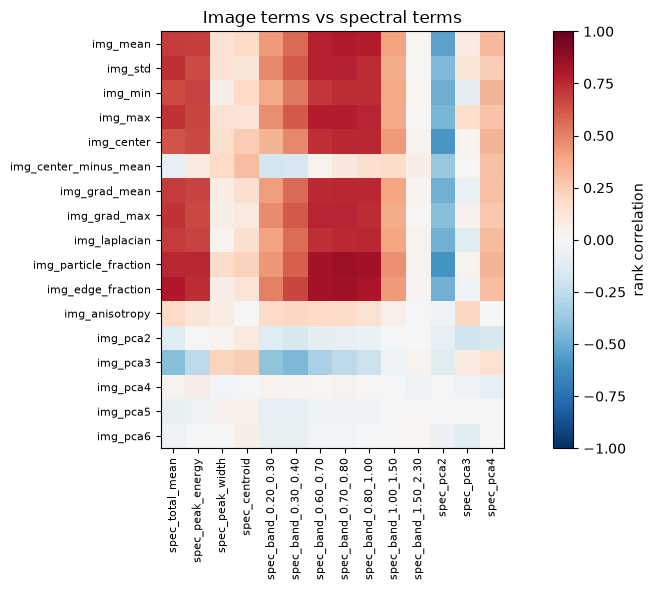

image    : ['img_mean', 'img_std', 'img_min', 'img_max', 'img_center', 'img_center_minus_mean', 'img_grad_mean', 'img_grad_max', 'img_laplacian', 'img_particle_fraction', 'img_edge_fraction', 'img_anisotropy', 'img_pca2', 'img_pca3', 'img_pca4', 'img_pca5', 'img_pca6']
spectral : ['spec_total_mean', 'spec_peak_energy', 'spec_peak_width', 'spec_centroid', 'spec_band_0.20_0.30', 'spec_band_0.30_0.40', 'spec_band_0.60_0.70', 'spec_band_0.70_0.80', 'spec_band_0.80_1.00', 'spec_band_1.00_1.50', 'spec_band_1.50_2.30', 'spec_pca2', 'spec_pca3', 'spec_pca4']
position : ['pos_row', 'pos_col', 'pos_dist_border', 'pos_dist_center']


In [10]:
# ============================================================
# STEP 4 — REMOVE DUPLICATE TERMS
# ============================================================
# If two terms rank all pixels almost the same way, the agent's choices
# cannot tell them apart, and the GA would waste time jumping between them.
# So we keep ONE term from every group of near-copies and remember
# which others it stands for (useful when we explain the result later).
#
# "Almost the same" = rank correlation above 0.95.
# We use RANK correlation: two terms that order pixels the same way are
# duplicates for choosing, even if one is e.g. the square of the other.
#
# Which one is kept? The first one in column order. The tables are already
# ordered "simple physical terms first, PCA last", so we keep the term
# that is easiest to explain.
#
# Duplicates are removed only INSIDE each group (image / spectral / position),
# because image and spectral terms enter the agent model in different ways
# (image: seen directly; spectral: only through the measured history).

THRESHOLD = 0.95

def rank_correlation(df):
    """Correlation of the RANKS of every pair of columns."""
    ranks = df.rank().values
    return pd.DataFrame(np.corrcoef(ranks, rowvar=False), index=df.columns, columns=df.columns)


def remove_duplicates(df, threshold=THRESHOLD):
    df = df.loc[:, df.std() > 0]               # drop terms that are constant (carry no information)
    corr = rank_correlation(df).abs()
    kept = []                                  # terms we keep
    merged_into = {}                           # kept term -> list of the duplicates it stands for
    for name in df.columns:
        # is this term a near-copy of one we already kept?
        twin = next((k for k in kept if corr.loc[name, k] > threshold), None)
        if twin is None:
            kept.append(name)
            merged_into[name] = []
        else:
            merged_into[twin].append(f"{name} ({corr.loc[name, twin]:.2f})")
    return df[kept], merged_into


groups = {"image": image_terms, "spectral": spectral_terms, "position": position_terms}
clean = {}         # the cleaned tables, used from now on
stands_for = {}    # for explaining results later

for gname, df in groups.items():
    clean[gname], stands_for[gname] = remove_duplicates(df)
    print(f"\n{gname}: {df.shape[1]} terms -> {clean[gname].shape[1]} kept")
    for k, dups in stands_for[gname].items():
        if dups:
            print(f"   {k:24s} also stands for: {', '.join(dups)}")


# ------------------------------------------------------------
# WARNING TABLE: image terms that look like spectral terms
# ------------------------------------------------------------
# If an image term and a spectral term rank pixels the same way, an agent
# chasing one looks like an agent chasing the other. We do not remove them
# (they enter the model differently), but we must remember this when we
# read the GA result.

cross = rank_correlation(pd.concat([clean["image"], clean["spectral"]], axis=1))
cross = cross.loc[clean["image"].columns, clean["spectral"].columns]

print("\nStrongest image <-> spectral links (rank correlation):")
print(cross.abs().stack().sort_values(ascending=False).head(8).round(2))

plt.figure(figsize=(10, 6))
plt.imshow(cross.values, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(cross.shape[1]), cross.columns, rotation=90, fontsize=8)
plt.yticks(range(cross.shape[0]), cross.index, fontsize=8)
plt.colorbar(label="rank correlation")
plt.title("Image terms vs spectral terms")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STANDARDIZED COPIES (mean 0, std 1) — used for similarity in step 5
# ------------------------------------------------------------
# Standardized so that "distance between two patches" is not dominated
# by a term that just has big numbers.
clean_z = {g: (df - df.mean()) / df.std() for g, df in clean.items()}

for g, df in clean.items():
    print(f"{g:9s}: {list(df.columns)}")

In [12]:
# ============================================================
# STEP 5 — REPLAY EVERY TRACE: WHAT DID THE AGENT KNOW AT EACH STEP?
# ============================================================
# For every trace and every step t we store:
#   - the 20 candidates and which one was chosen
#   - the HISTORY: pixels measured before step t (10 initial points for DKL + earlier choices)
#   - history terms for each candidate (distance to last point, novelty, ...)
#   - for the spectral surrogate: the matrices needed to predict
#     "how good does this candidate look, judged from the measured patches"
#
# The trick (from our plan): the surrogate's prediction is
#       mu = A_t @ (reward values of the history)
# and A_t depends only on the PATCHES, not on which reward we guess.
# So we build A_t once here, and in the GA every guessed reward costs
# only one matrix multiplication.
#
# Rule: NOTHING measured at step t or later is used to explain step t.

# --- settings ---
GP_FEATURES = clean_z["image"].values               # how we describe a patch: the 17 standardized image terms
MEMORY_LEVELS = [1, 3, 10, 30, np.inf]              # how many past steps the agent "remembers" (inf = everything)
LENGTHSCALE = 0.7 * np.sqrt(GP_FEATURES.shape[1] / 6)   # how similar two patches must be to "count" as similar
GP_NOISE = 0.05                                     # how much the surrogate trusts each measurement
MIN_HISTORY = 3                                     # fewer measured points than this -> no spectral prediction yet
K_NOVELTY = 5                                       # novelty = mean distance to the 5 most similar measured patches
RADIUS_PX = 8                                       # "crowded" = measured points within 8 pixels

row_of, col_of = np.divmod(np.arange(H * W), W)     # pixel number -> row, column
DIAG = np.hypot(H, W)                               # image diagonal, to make distances 0..1


def rbf(A, B, ell=LENGTHSCALE):
    """Similarity between every row of A and every row of B: 1 = identical, 0 = very different."""
    d2 = ((A[:, None, :] - B[None, :, :]) ** 2).sum(-1)
    return np.exp(-0.5 * d2 / ell ** 2)


def replay_trace(trace):
    # history starts with the initial points (DKL traces have 10, human traces have none)
    history = [int(p["spectrum_index"]) for p in trace.get("initialization", [])]

    out = {"cand": [], "winner": [], "hist": [], "step": [], "has_history": [],
           "X_hist": [], "K_ch": [],
           "A": {m: [] for m in MEMORY_LEVELS}, "sigma": {m: [] for m in MEMORY_LEVELS}}
    n_steps = len(trace["decisions"])

    for d in trace["decisions"]:
        cand = np.array(d["candidate_indices"], dtype=int)   # the 20 candidates (pixel numbers)
        winner = int(d["selected_position"])                 # which of the 20 was chosen (0..19)
        h = np.array(history, dtype=int)                     # what was measured BEFORE this step
        n = len(h)
        cr, cc = row_of[cand], col_of[cand]

        # ---------- spatial and similarity terms ----------
        if n > 0:
            hr, hc = row_of[h], col_of[h]
            dist_px = np.hypot(cr[:, None] - hr[None], cc[:, None] - hc[None])   # (20, n) pixel distances
            dist_last = dist_px[:, -1] / DIAG                     # how far from the last measured point
            dist_nearest = dist_px.min(1) / DIAG                  # how far from ANY measured point
            crowd = (dist_px < RADIUS_PX).sum(1).astype(float)    # how many measured points are close by

            fd = np.sqrt(((GP_FEATURES[cand][:, None] - GP_FEATURES[h][None]) ** 2).sum(-1))   # (20, n) look-alike distances
            novelty = np.sort(fd, axis=1)[:, :min(K_NOVELTY, n)].mean(1)    # looks unlike what was measured
            sim_last = np.exp(-0.5 * fd[:, -1] ** 2 / LENGTHSCALE ** 2)     # looks like the last measured patch
        else:
            dist_last = dist_nearest = crowd = novelty = sim_last = np.zeros(len(cand))

        if n >= 2:
            # does the move keep the same direction as the previous move? (+1 same, -1 back)
            v_last = np.array([hr[-1] - hr[-2], hc[-1] - hc[-2]], float)
            v_new = np.stack([cr - hr[-1], cc - hc[-1]], 1).astype(float)
            same_direction = v_new @ v_last / (np.linalg.norm(v_new, axis=1) * np.linalg.norm(v_last) + 1e-12)
        else:
            same_direction = np.zeros(len(cand))

        X_hist = np.stack([dist_last, dist_nearest, crowd, same_direction, novelty, sim_last,
                           np.full(len(cand), d["step"] / n_steps)], axis=1)     # (20, 7)

        # ---------- spectral surrogate (one A_t per memory level) ----------
        has_history = n >= MIN_HISTORY
        if has_history:
            K_ch = rbf(GP_FEATURES[cand], GP_FEATURES[h])     # candidates vs history
            K_hh = rbf(GP_FEATURES[h], GP_FEATURES[h])        # history vs history
            age = np.arange(n)[::-1].astype(float)            # 0 = newest measurement
            for m in MEMORY_LEVELS:
                # forgetting: old points get a large "noise", so they count less
                weight = np.ones(n) if np.isinf(m) else np.exp(-age / m)
                noise = GP_NOISE / np.maximum(weight, 1e-6)
                A = np.linalg.solve(K_hh + np.diag(noise), K_ch.T).T          # (20, n)
                sig = np.sqrt(np.clip(1 - (A * K_ch).sum(1), 1e-9, None))     # uncertainty, (20,)
                out["A"][m].append(A)
                out["sigma"][m].append(sig)
        else:
            K_ch = np.zeros((len(cand), n))
            for m in MEMORY_LEVELS:
                out["A"][m].append(np.zeros((len(cand), n)))
                out["sigma"][m].append(np.ones(len(cand)))

        # ---------- store ----------
        out["cand"].append(cand)
        out["winner"].append(winner)
        out["hist"].append(h)
        out["step"].append(d["step"])
        out["has_history"].append(has_history)
        out["X_hist"].append(X_hist)
        out["K_ch"].append(K_ch)        # kept for g-dependent terms later ("looks like the best so far")

        # the chosen spectrum is revealed AFTER the choice -> joins the history for the next step
        history.append(int(d["selected_index"]))

    # lists -> arrays where all steps have the same shape
    out["cand"] = np.array(out["cand"])
    out["winner"] = np.array(out["winner"])
    out["step"] = np.array(out["step"])
    out["has_history"] = np.array(out["has_history"])
    out["X_hist"] = np.array(out["X_hist"])                         # (steps, 20, 7)
    for m in MEMORY_LEVELS:
        out["sigma"][m] = np.array(out["sigma"][m])                 # (steps, 20)
    out["X_img"] = clean_z["image"].values[out["cand"]]            # (steps, 20, 17)  seen directly
    out["X_pos"] = clean_z["position"].values[out["cand"]]         # (steps, 20, 4)
    return out


HIST_NAMES = ["hist_dist_last", "hist_dist_nearest", "hist_crowd", "hist_same_direction",
              "hist_novelty", "hist_sim_last", "hist_time"]
trace_names = {i: f.stem for i, f in enumerate(trace_files)}

replays = {}
for tid, tr in traces.items():
    replays[tid] = replay_trace(tr)
    r = replays[tid]
    first = r["step"][r["has_history"]][0]
    print(f"Trace {tid} ({trace_names[tid]}): {len(r['winner'])} steps, spectral prediction from step {first}")


# ------------------------------------------------------------
# HELPER: predicted value mu of a guessed spectral reward g for every candidate
# ------------------------------------------------------------
def mu_for(replay, g, memory):
    """g = one value per pixel (e.g. a column of clean['spectral']).
    Returns (steps, 20): how good each candidate looks, judged ONLY from the history."""
    mus = []
    for h, A, ok in zip(replay["hist"], replay["A"][memory], replay["has_history"]):
        if not ok:
            mus.append(np.zeros(A.shape[0]))
            continue
        y = g[h]
        y = (y - y.mean()) / (y.std() + 1e-12)     # the agent cares about better/worse, not absolute units
        mus.append(A @ y)
    return np.array(mus)


# ------------------------------------------------------------
# CHECK: does the surrogate carry information? (no fitting yet)
# ------------------------------------------------------------
# For the true DKL reward (spectral mean), how often is the real choice
# among the 5 candidates with the highest predicted mu?
# Chance = 5 / 20 = 25%. With SHUFFLED spectra it should drop toward chance.

def top5_rate(score, replay):
    ok = replay["has_history"]
    return np.mean([(np.argsort(-s)[:5] == w).any() for s, w in zip(score[ok], replay["winner"][ok])])

g_test = clean["spectral"]["spec_total_mean"].values
rng = np.random.default_rng(0)

print(f"\n{'trace':22s} {'mu (real spectra)':>18s} {'mu (shuffled)':>15s}   chance = 25%")
for tid, r in replays.items():
    real = top5_rate(mu_for(r, g_test, np.inf), r)
    fake = top5_rate(mu_for(r, rng.permutation(g_test), np.inf), r)
    print(f"{trace_names[tid]:22s} {real:>18.0%} {fake:>15.0%}")

Trace 0 (eels_ei_trace): 200 steps, spectral prediction from step 1
Trace 1 (eels_random_trace): 200 steps, spectral prediction from step 1
Trace 2 (eels_ucb_trace): 200 steps, spectral prediction from step 1
Trace 3 (trace_P01_eels_): 100 steps, spectral prediction from step 4
Trace 4 (trace_P03_eels): 100 steps, spectral prediction from step 4

trace                   mu (real spectra)   mu (shuffled)   chance = 25%
eels_ei_trace                         62%             33%
eels_random_trace                     22%             20%
eels_ucb_trace                        50%             30%
trace_P01_eels_                       61%             11%
trace_P03_eels                        56%             20%


In [ ]:
# # ============================================================
# # STEP 6 — THE FITNESS FUNCTION
# # ============================================================
# # A GENOME is one guess of the agent's rule, written as a dict:
# #   {
# #     "img":  ["img_edge_fraction", ...],        image terms (seen directly)
# #     "pos":  ["pos_row", ...],                  position terms
# #     "hist": ["hist_dist_last", ...],           history terms (spatial / similarity / time)
# #     "spec": {"kind": "column", "name": "spec_total_mean"}      a spectral reward g
# #          or {"kind": "window", "E1": 0.3, "E2": 0.7},          mean in any energy window
# #     "memory": np.inf,                           how far back the agent remembers (one of MEMORY_LEVELS)
# #     "use_sigma": True,                          also use the surrogate's uncertainty (exploration)
# #     "use_best":  False,                         also use "looks like the best measured patch so far"
# #   }
# # Every key is optional. An empty genome {} = "the agent chooses at random".
# #
# # FITNESS(genome) = how well this rule predicts the real choices on steps
# # it was NOT fitted on, minus a small cost per term.

# N_FOLDS = 5             # split the steps into 5 time blocks for honest testing
# L2 = 1.0                # keeps weights from growing huge (mild regularization)
# COST_PER_TERM = 0.005   # price of every extra term -> simple explanations win
# N_CAND = 20

# # --- spectral reward values per pixel (cached, so each g is computed only once) ---
# _g_cache = {}

# def spectral_values(spec):
#     key = tuple(sorted(spec.items()))
#     if key not in _g_cache:
#         if spec["kind"] == "column":
#             _g_cache[key] = clean["spectral"][spec["name"]].values
#         else:                                               # any energy window, from step 3
#             _g_cache[key] = window_mean(spec["E1"], spec["E2"])
#     return _g_cache[key]


# # --- 1 + 2: turn a genome into a feature array (steps, 20, number of terms) ---
# def build_features(genome, replay):
#     cols, names = [], []

#     for name in genome.get("img", []):                        # image terms
#         k = clean["image"].columns.get_loc(name)
#         cols.append(replay["X_img"][:, :, k]); names.append(name)

#     for name in genome.get("pos", []):                        # position terms
#         k = clean["position"].columns.get_loc(name)
#         cols.append(replay["X_pos"][:, :, k]); names.append(name)

#     for name in genome.get("hist", []):                       # history terms
#         k = HIST_NAMES.index(name)
#         cols.append(replay["X_hist"][:, :, k]); names.append(name)

#     spec = genome.get("spec")
#     if spec is not None:                                      # spectral terms (through the surrogate)
#         g = spectral_values(spec)
#         m = genome.get("memory", np.inf)
#         label = spec["name"] if spec["kind"] == "column" else f"window[{spec['E1']:.2f},{spec['E2']:.2f}]"

#         cols.append(mu_for(replay, g, m)); names.append(f"mu({label}, mem={m})")       # exploit

#         if genome.get("use_sigma", False):                                              # explore
#             cols.append(replay["sigma"][m]); names.append(f"sigma(mem={m})")

#         if genome.get("use_best", False):                                               # go back to what worked
#             best = [K[:, np.argmax(g[h])] if ok else np.zeros(N_CAND)
#                     for h, K, ok in zip(replay["hist"], replay["K_ch"], replay["has_history"])]
#             cols.append(np.array(best)); names.append(f"looks_like_best({label})")

#     if not cols:                                              # empty genome = random agent
#         return np.zeros((len(replay["winner"]), N_CAND, 0)), names

#     X = np.stack(cols, axis=2)                                # (steps, 20, terms)
#     X = X - X.mean(axis=1, keepdims=True)                     # only differences between the 20 candidates matter
#     X = X / (X.std(axis=(0, 1), keepdims=True) + 1e-12)       # every term on the same scale
#     return X, names


# # --- 3: the choice model and its exact fit ---
# def log_probs(X, w):
#     """log P(each candidate is chosen) = softmax of the scores X @ w, for every step."""
#     U = X @ w
#     U = U - U.max(axis=1, keepdims=True)                      # avoids overflow, changes nothing
#     return U - np.log(np.exp(U).sum(axis=1, keepdims=True))


# def fit_weights(X, winners, l2=L2, n_iter=30):
#     """Weights that make the real choices most probable.
#     Newton's method: the problem is convex (one best answer), so this is fast and safe."""
#     S, C, K = X.shape
#     w = np.zeros(K)
#     if K == 0:
#         return w
#     rows = np.arange(S)

#     def objective(w):
#         return -log_probs(X, w)[rows, winners].sum() + 0.5 * l2 * w @ w

#     for _ in range(n_iter):
#         p = np.exp(log_probs(X, w))                           # (S, 20) probabilities
#         x_win = X[rows, winners]                              # terms of the real choices
#         x_avg = np.einsum("sc,sck->sk", p, X)                 # terms the model expects
#         grad = -(x_win - x_avg).sum(0) + l2 * w
#         Xc = X - x_avg[:, None, :]
#         hess = np.einsum("sc,sck,scl->kl", p, Xc, Xc) + l2 * np.eye(K)
#         step = np.linalg.solve(hess, grad)

#         f_old, t = objective(w), 1.0                          # shrink the step if it does not help
#         while objective(w - t * step) > f_old and t > 1e-4:
#             t /= 2
#         w = w - t * step
#         if np.abs(t * step).max() < 1e-6:                     # converged
#             break
#     return w


# # --- 5: the score ---
# def explained(X, winners, w):
#     """0 = no better than random guessing, 1 = every choice predicted with certainty."""
#     lp = log_probs(X, w)[np.arange(len(winners)), winners]
#     return 1 - lp.sum() / (len(winners) * np.log(1 / N_CAND))


# # --- 4 + 5: the fitness, tested on blocks of steps the fit has not seen ---
# def fitness(genome, replay, return_details=False):
#     X, names = build_features(genome, replay)
#     winners = replay["winner"]
#     S = len(winners)

#     folds = np.array_split(np.arange(S), N_FOLDS)            # 5 blocks in TIME order
#     test_score, hits = 0.0, 0
#     for test in folds:
#         train = np.setdiff1d(np.arange(S), test)
#         w = fit_weights(X[train], winners[train])
#         test_score += explained(X[test], winners[test], w) * len(test)
#         hits += (np.argmax(X[test] @ w, axis=1) == winners[test]).sum()

#     score_heldout = test_score / S
#     fit = score_heldout - COST_PER_TERM * len(names)
#     if not return_details:
#         return fit

#     w_all = fit_weights(X, winners)                           # final weights on all steps, for reading
#     return {"fitness": fit,
#             "explained_heldout": score_heldout,
#             "accuracy_heldout": hits / S,                     # how often the top-scored candidate was the real choice
#             "explained_in_sample": explained(X, winners, w_all),
#             "weights": dict(zip(names, np.round(w_all, 2)))}  # + = agent seeks this, - = agent avoids it


# # ------------------------------------------------------------
# # TRY IT: score a few hand-written guesses on every trace
# # ------------------------------------------------------------
# spec_mean = {"kind": "column", "name": "spec_total_mean"}
# examples = {
#     "nothing (= random guess)":         {},
#     "image: edge fraction":             {"img": ["img_edge_fraction"]},
#     "image: 3 terms":                   {"img": ["img_edge_fraction", "img_std", "img_pca3"]},
#     "spectral mean (exploit)":          {"spec": spec_mean, "memory": np.inf},
#     "spectral mean + sigma (UCB-like)": {"spec": spec_mean, "memory": np.inf, "use_sigma": True},
#     "image + spectral":                 {"img": ["img_edge_fraction", "img_std"],
#                                          "spec": spec_mean, "memory": np.inf, "use_sigma": True},
#     "spatial only":                     {"hist": ["hist_dist_last", "hist_dist_nearest", "hist_novelty"]},
# }

# table = pd.DataFrame({name: {trace_names[t]: fitness(gen, r) for t, r in replays.items()}
#                       for name, gen in examples.items()}).T
# pd.set_option("display.width", 200)
# print(table.round(3))

# # details of one guess: which terms matter and in which direction
# print(fitness(examples["image + spectral"], replays[2], return_details=True))

In [18]:
# ============================================================
# STEP 5b — THE FLAT BANK OF ITEMS
# ============================================================
# Every possible term becomes ONE item: an array (steps, 20) per trace
# = "the value of this term for each of the 20 candidates at each step".
# The GA picks items freely from this one flat list.
#
# The "what did the agent know" rule is built in HERE, once:
#   - image / position items: the agent saw them directly
#   - history items: computed from the measured points before the step (step 5)
#   - spectral items: a candidate's spectrum is NOT known before measuring, so a
#     spectral reward g only appears through the history:
#         mu(g, mem)        how good the candidate looks, judged from measured patches
#         sigma(mem)        how unexplored the candidate is
#         best(g)           looks like the best measured patch so far
#         stay_if_good(g)   looks like the last patch, AND the last result was good

N_CAND = 20

# --- all spectral rewards g: the cleaned spectral terms + mean in many energy windows ---
EDGES = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.5, 2.3]     # eV; fine where the peaks are
reward_names, reward_values = [], []
for name in clean["spectral"].columns:
    reward_names.append(name)
    reward_values.append(clean["spectral"][name].values)
for i in range(len(EDGES)):
    for j in range(i + 1, len(EDGES)):
        reward_names.append(f"win_{EDGES[i]:.2f}_{EDGES[j]:.2f}")
        reward_values.append(window_mean(EDGES[i], EDGES[j]))
G = np.stack(reward_values, axis=1)          # (pixels, number of rewards): value of every g at every pixel
print("Spectral rewards g:", G.shape[1])     # expected: 69


def mem_label(m):
    return "all" if np.isinf(m) else str(int(m))


def build_bank(replay, G=G):
    S = len(replay["winner"])
    items, family = {}, {}

    def add(name, fam, values):
        items[name] = values.astype(np.float32)
        family[name] = fam

    # --- items the agent sees directly, or knows from its history ---
    for k, name in enumerate(clean["image"].columns):
        add(name, "image", replay["X_img"][:, :, k])
    for k, name in enumerate(clean["position"].columns):
        add(name, "position", replay["X_pos"][:, :, k])
    for k, name in enumerate(HIST_NAMES):
        add(name, "history", replay["X_hist"][:, :, k])
    for m in MEMORY_LEVELS:
        add(f"sigma(mem={mem_label(m)})", "sigma", replay["sigma"][m])

    # --- spectral items: all rewards at once, step by step, using ONLY the history ---
    mu = {m: np.zeros((S, N_CAND, G.shape[1])) for m in MEMORY_LEVELS}
    best = np.zeros((S, N_CAND, G.shape[1]))
    stay = np.zeros((S, N_CAND, G.shape[1]))
    sim_last = replay["X_hist"][:, :, HIST_NAMES.index("hist_sim_last")]

    for s in range(S):
        if not replay["has_history"][s]:
            continue                                         # too few measurements yet -> stays 0
        h = replay["hist"][s]
        Y = G[h]                                             # rewards of the measured points (n, rewards)
        Yz = (Y - Y.mean(0)) / (Y.std(0) + 1e-12)            # better / worse than average, per reward
        for m in MEMORY_LEVELS:
            mu[m][s] = replay["A"][m][s] @ Yz                # (20, rewards)
        best[s] = replay["K_ch"][s][:, np.argmax(Y, axis=0)] # similarity to the best measured patch
        stay[s] = Yz[-1][None, :] * sim_last[s][:, None]     # last result x looks like the last patch

    for gi, gname in enumerate(reward_names):
        for m in MEMORY_LEVELS:
            add(f"mu({gname}, mem={mem_label(m)})", "mu", mu[m][:, :, gi])
        add(f"best({gname})", "best", best[:, :, gi])
        add(f"stay_if_good({gname})", "stay", stay[:, :, gi])

    # --- one big array, every item made comparable ---
    names = list(items)
    X = np.stack([items[n] for n in names], axis=2)          # (steps, 20, items)
    X = X - X.mean(axis=1, keepdims=True)                    # only differences between the 20 candidates matter
    X = X / (X.std(axis=(0, 1), keepdims=True) + 1e-12)      # same scale for every item
    X = np.clip(X, -5, 5)                                    # cut extreme values so one odd step cannot dominate

    return {"X": X.astype(np.float32),
            "names": names,
            "index": {n: i for i, n in enumerate(names)},    # item name -> column number
            "family": family,
            "winner": replay["winner"]}


banks = {tid: build_bank(r) for tid, r in replays.items()}
ITEM_NAMES = banks[0]["names"]          # the same list for every trace
ITEM_FAMILY = banks[0]["family"]        # used only for the first population and for reading results

print("Items in the bank:", len(ITEM_NAMES))                 # expected: 516
print(pd.Series(ITEM_FAMILY).value_counts().to_string())
print(f"Bank size per trace: {banks[0]['X'].nbytes / 1e6:.1f} MB")

Spectral rewards g: 69
Items in the bank: 516
mu          345
best         69
stay         69
image        17
history       7
sigma         5
position      4
Bank size per trace: 8.3 MB


In [19]:
# ============================================================
# STEP 6 (NEW) — FITNESS OF A GENOME = A LIST OF ITEM NAMES
# ============================================================
# A genome is now just a list, e.g.
#   ["img_edge_fraction", "hist_dist_last", "mu(win_0.30_0.60, mem=10)"]
# An empty list [] = "the agent chooses at random".
#
# fitness = how well the genome predicts the real choices on steps the
#           fit has NOT seen (0 = random guessing), minus a small cost per item.

N_FOLDS = 5             # 5 time blocks: fit on 4, predict the 5th, repeat
L2 = 1.0                # keeps weights from growing huge
COST_PER_TERM = 0.005   # price of every extra item -> simple explanations win


def log_probs(X, w):
    """log P(each candidate is chosen) = softmax of the scores X @ w, for every step."""
    U = X @ w
    U = U - U.max(axis=1, keepdims=True)                     # avoids overflow, changes nothing
    return U - np.log(np.exp(U).sum(axis=1, keepdims=True))


def fit_weights(X, winners, l2=L2, n_iter=30):
    """Weights that make the real choices most probable (Newton's method; the problem
    is convex, so there is one best answer and no guessing)."""
    S, C, K = X.shape
    w = np.zeros(K)
    if K == 0:
        return w
    rows = np.arange(S)

    def objective(w):
        return -log_probs(X, w)[rows, winners].sum() + 0.5 * l2 * w @ w

    for _ in range(n_iter):
        p = np.exp(log_probs(X, w))
        x_win = X[rows, winners]                              # items of the real choices
        x_avg = np.einsum("sc,sck->sk", p, X)                 # items the model expects
        grad = -(x_win - x_avg).sum(0) + l2 * w
        Xc = X - x_avg[:, None, :]
        hess = np.einsum("sc,sck,scl->kl", p, Xc, Xc) + l2 * np.eye(K)
        step = np.linalg.solve(hess, grad)
        f_old, t = objective(w), 1.0                          # shrink the step if it does not help
        while objective(w - t * step) > f_old and t > 1e-4:
            t /= 2
        w = w - t * step
        if np.abs(t * step).max() < 1e-6:
            break
    return w


def explained(X, winners, w):
    """0 = no better than random guessing, 1 = every choice predicted with certainty."""
    lp = log_probs(X, w)[np.arange(len(winners)), winners]
    return 1 - lp.sum() / (len(winners) * np.log(1 / N_CAND))


def fitness(genome, bank, return_details=False):
    idx = [bank["index"][name] for name in genome]
    X = bank["X"][:, :, idx].astype(np.float64)
    winners = bank["winner"]
    S = len(winners)

    test_score, hits = 0.0, 0
    for test in np.array_split(np.arange(S), N_FOLDS):       # blocks in TIME order
        train = np.setdiff1d(np.arange(S), test)
        w = fit_weights(X[train], winners[train])
        test_score += explained(X[test], winners[test], w) * len(test)
        hits += (np.argmax(X[test] @ w, axis=1) == winners[test]).sum()

    score_heldout = test_score / S
    fit = score_heldout - COST_PER_TERM * len(genome)
    if not return_details:
        return fit

    w_all = fit_weights(X, winners)                           # final weights on all steps, for reading
    return {"fitness": round(fit, 4),
            "explained_heldout": round(score_heldout, 4),
            "accuracy_heldout": round(hits / S, 3),           # top-scored candidate = real choice
            "explained_in_sample": round(explained(X, winners, w_all), 4),
            "weights": dict(zip(genome, np.round(w_all, 2)))} # + = agent seeks it, - = agent avoids it


# ------------------------------------------------------------
# TRY IT: the same guesses as before, now as item lists
# ------------------------------------------------------------
examples = {
    "nothing (= random guess)":         [],
    "image: edge fraction":             ["img_edge_fraction"],
    "image: 3 terms":                   ["img_edge_fraction", "img_std", "img_pca3"],
    "spectral mean (exploit)":          ["mu(spec_total_mean, mem=all)"],
    "spectral mean + sigma (UCB-like)": ["mu(spec_total_mean, mem=all)", "sigma(mem=all)"],
    "window 0.3-0.6 eV, memory 10":     ["mu(win_0.30_0.60, mem=10)"],
    "image + spectral":                 ["img_edge_fraction", "img_std",
                                         "mu(spec_total_mean, mem=all)", "sigma(mem=all)"],
    "spatial only":                     ["hist_dist_last", "hist_dist_nearest", "hist_novelty"],
    "go back to best (mean)":           ["best(spec_total_mean)"],
}

short = {0: "EI", 1: "random", 2: "UCB", 3: "P01", 4: "P03"}
table = pd.DataFrame({name: {short[t]: fitness(gen, b) for t, b in banks.items()}
                      for name, gen in examples.items()}).T
pd.set_option("display.width", 200)
print(table.round(3))

print(fitness(examples["image + spectral"], banks[2], return_details=True))

                                     EI  random    UCB    P01    P03
nothing (= random guess)          0.000   0.000  0.000  0.000  0.000
image: edge fraction              0.021  -0.006 -0.006  0.136  0.293
image: 3 terms                    0.200  -0.020  0.061  0.181  0.330
spectral mean (exploit)           0.105  -0.007  0.025  0.163  0.206
spectral mean + sigma (UCB-like)  0.130  -0.012  0.026  0.147  0.202
window 0.3-0.6 eV, memory 10      0.081  -0.007  0.028  0.118  0.146
image + spectral                  0.185  -0.021  0.088  0.184  0.308
spatial only                      0.031  -0.023 -0.036  0.125  0.377
go back to best (mean)           -0.013  -0.011 -0.668 -0.001  0.008
{'fitness': np.float64(0.0884), 'explained_heldout': np.float64(0.1084), 'accuracy_heldout': np.float64(0.255), 'explained_in_sample': np.float64(0.133), 'weights': {'img_edge_fraction': np.float64(-0.88), 'img_std': np.float64(1.4), 'mu(spec_total_mean, mem=all)': np.float64(0.85), 'sigma(mem=all)': np.float

In [20]:
# ============================================================
# BALANCED RANDOM CHOICE OF ITEMS (used by the GA in step 8)
# ============================================================
# Problem: 345 of the 516 items are mu-variants. Picking items uniformly
# would make ~67% of every new guess spectral, just because there are more of them.
# Fix: first pick a FAMILY (all families equally likely), then an item inside it.
# This only decides what is PROPOSED. Which items survive is decided by fitness alone.

FAMILIES = sorted(set(ITEM_FAMILY.values()))                       # best, history, image, mu, position, sigma, stay
ITEMS_BY_FAMILY = {f: [n for n in ITEM_NAMES if ITEM_FAMILY[n] == f] for f in FAMILIES}


def random_item(rng, exclude=()):
    """One random item: family first (equal chances), then an item of that family."""
    while True:
        fam = rng.choice(FAMILIES)
        name = str(rng.choice(ITEMS_BY_FAMILY[fam]))
        if name not in exclude:          # no item twice in the same genome
            return name


def random_genome(rng, min_size=1, max_size=5):
    """A random guess with 1 to 5 different items."""
    size = rng.integers(min_size, max_size + 1)
    genome = []
    while len(genome) < size:
        genome.append(random_item(rng, exclude=genome))
    return genome


# ------------------------------------------------------------
# CHECK: is the balancing working?
# ------------------------------------------------------------
rng = np.random.default_rng(42)
population = [random_genome(rng) for _ in range(2000)]
picked = pd.Series([ITEM_FAMILY[n] for g in population for n in g])

compare = pd.DataFrame({
    "share in bank":           pd.Series(ITEM_FAMILY).value_counts(normalize=True),
    "share in random genomes": picked.value_counts(normalize=True),
}).round(3)
print(compare)
print("Example genome:", random_genome(rng))

          share in bank  share in random genomes
best              0.134                    0.149
history           0.014                    0.143
image             0.033                    0.148
mu                0.669                    0.143
position          0.008                    0.135
sigma             0.010                    0.139
stay              0.134                    0.142
Example genome: ['stay_if_good(win_0.40_2.30)', 'img_grad_max', 'hist_sim_last', 'mu(win_0.30_0.60, mem=10)', 'pos_col']


In [21]:
# ============================================================
# STEP 7 — SANITY CHECKS: CAN WE TRUST THE FITNESS FUNCTION?
# ============================================================
# Before the GA climbs the fitness, we test it on cases where WE know the answer.
#   A. Planted agents: we invent a rule, make fake choices with it on real
#      candidate sets, and check that the fitness finds that rule again.
#   B. The random trace: nothing should score above 0. The best score found
#      there is our NOISE FLOOR (what "pure luck" looks like).
#   C. Shuffle the spectra: spectral items should lose their power for agents
#      that really use the spectra, and stay the same for agents that do not.

rng = np.random.default_rng(7)
SPECTRAL_FAMILIES = {"mu", "best", "stay"}
short = {0: "EI", 1: "random", 2: "UCB", 3: "P01", 4: "P03"}


def scan_single_items(bank, families=None):
    """Fitness of every single item on its own, best first."""
    names = [n for n in ITEM_NAMES if families is None or ITEM_FAMILY[n] in families]
    scores = pd.Series({n: fitness([n], bank) for n in names})
    return scores.sort_values(ascending=False)


# ------------------------------------------------------------
# TEST A — planted agents (on the real candidate sets of the UCB trace)
# ------------------------------------------------------------
print("=" * 70 + "\nTEST A: planted agents\n" + "=" * 70)
base = banks[2]
planted_rules = {
    "image agent":    {"img_edge_fraction": 1.5},                                  # likes edges
    "spectral agent": {"mu(win_0.30_0.60, mem=10)": 2.0, "sigma(mem=10)": 1.0},    # UCB-like, memory 10
    "spatial agent":  {"hist_dist_last": -2.0},                                    # makes short steps
}

for rule_name, rule in planted_rules.items():
    genome = list(rule)
    w = np.array(list(rule.values()))

    # fake choices: the planted rule + randomness (softmax), on the real candidates
    X = base["X"][:, :, [base["index"][n] for n in genome]].astype(np.float64)
    p = np.exp(log_probs(X, w))
    fake_winners = np.array([rng.choice(N_CAND, p=pi / pi.sum()) for pi in p])
    fake_bank = dict(base, winner=fake_winners)

    details = fitness(genome, fake_bank, return_details=True)
    top = scan_single_items(fake_bank)
    rank = {n: int(np.where(top.index == n)[0][0]) + 1 for n in genome}

    print(f"\n{rule_name}: planted {rule}")
    print(f"   fitness of the planted genome: {details['fitness']:.3f}")
    print(f"   recovered weights:             {details['weights']}")
    print(f"   rank of each planted item among all {len(top)} single items: {rank}")
    print(f"   top 3 single items: {list(top.index[:3])}")


# ------------------------------------------------------------
# TEST B — the random trace: the noise floor
# ------------------------------------------------------------
print("\n" + "=" * 70 + "\nTEST B: the random trace (noise floor)\n" + "=" * 70)
scan_random = scan_single_items(banks[1])
NOISE_FLOOR = scan_random.iloc[0]
print(f"Best single item on the random trace: {scan_random.index[0]}  fitness = {NOISE_FLOOR:.3f}")
print(f"Share of items above 0: {(scan_random > 0).mean():.0%}")


# ------------------------------------------------------------
# TEST C — shuffle the spectra (keeps their values, breaks the link to the image)
# ------------------------------------------------------------
print("\n" + "=" * 70 + "\nTEST C: shuffle the spectra\n" + "=" * 70)
N_SHUFFLES = 3
rows = []
for tid, r in replays.items():
    real = scan_single_items(banks[tid], SPECTRAL_FAMILIES)
    fake_best = []
    for _ in range(N_SHUFFLES):
        perm = rng.permutation(G.shape[0])                     # give every pixel the spectra of a random other pixel
        fake_bank = build_bank(r, G=G[perm])
        fake_best.append(scan_single_items(fake_bank, SPECTRAL_FAMILIES).iloc[0])
    rows.append({"trace": short[tid],
                 "best spectral item": real.index[0],
                 "fitness (real spectra)": round(real.iloc[0], 3),
                 "fitness (shuffled, mean)": round(np.mean(fake_best), 3),
                 "drop": round(real.iloc[0] - np.mean(fake_best), 3)})
print(pd.DataFrame(rows).set_index("trace").to_string())

TEST A: planted agents

image agent: planted {'img_edge_fraction': 1.5}
   fitness of the planted genome: 0.327
   recovered weights:             {'img_edge_fraction': np.float64(1.57)}
   rank of each planted item among all 516 single items: {'img_edge_fraction': 1}
   top 3 single items: ['img_edge_fraction', 'img_grad_mean', 'img_laplacian']

spectral agent: planted {'mu(win_0.30_0.60, mem=10)': 2.0, 'sigma(mem=10)': 1.0}
   fitness of the planted genome: 0.377
   recovered weights:             {'mu(win_0.30_0.60, mem=10)': np.float64(2.0), 'sigma(mem=10)': np.float64(1.25)}
   rank of each planted item among all 516 single items: {'mu(win_0.30_0.60, mem=10)': 18, 'sigma(mem=10)': 228}
   top 3 single items: ['mu(win_0.40_0.60, mem=10)', 'mu(win_0.40_0.70, mem=10)', 'mu(win_0.20_1.00, mem=10)']

spatial agent: planted {'hist_dist_last': -2.0}
   fitness of the planted genome: 0.296
   recovered weights:             {'hist_dist_last': np.float64(-2.02)}
   rank of each planted item a


=== Trace 0 (EI) ===
  gen  0: best = 0.181, mean = 0.046, guesses tried = 77
  gen  5: best = 0.217, mean = 0.122, guesses tried = 417
  gen 10: best = 0.227, mean = 0.123, guesses tried = 743
  gen 15: best = 0.227, mean = 0.133, guesses tried = 1055
  gen 20: best = 0.238, mean = 0.145, guesses tried = 1357
  gen 25: best = 0.238, mean = 0.140, guesses tried = 1653
  gen 30: best = 0.238, mean = 0.137, guesses tried = 1941
  stopped at generation 34: no improvement for 15 generations
  BEST fitness = 0.238  (held-out explained = 0.263, accuracy = 39%, random = 5%)
     -0.47  img_pca3
     +0.36  img_pca5
     +1.26  mu(win_0.40_1.50, mem=all)
     -0.99  pos_col
     -0.30  pos_dist_center

=== Trace 1 (random) ===
  gen  0: best = -0.003, mean = -0.024, guesses tried = 80
  gen  5: best = -0.002, mean = -0.009, guesses tried = 365
  gen 10: best = -0.002, mean = -0.008, guesses tried = 593
  gen 15: best = -0.001, mean = -0.009, guesses tried = 793
  gen 20: best = -0.001, mean =

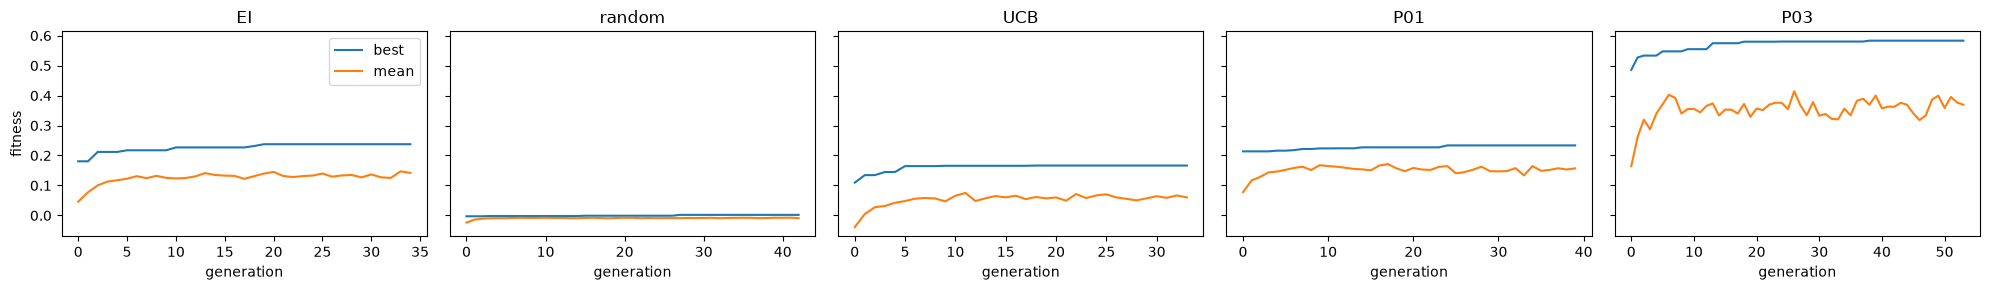

In [30]:
# ============================================================
# STEP 8 — THE GENETIC ALGORITHM
# ============================================================
# The loop, in plain words:
#   1. make 60 random guesses (genomes = lists of 1-5 items)
#   2. score every guess with the fitness (step 6)
#   3. keep the 6 best unchanged ("elite"), so the best is never lost
#   4. fill the rest of the new population with children:
#        - pick two parents by "tournament": take 3 random guesses, the best one wins
#        - crossover: the child takes a random mix of the parents' items
#        - mutation: one small random change (add / remove / swap an item)
#   5. repeat until the best score has not improved for 10 generations
#
# Every genome that was ever scored is kept with its score ("hall of fame"),
# so at the end we can look at the top-k explanations, not only the winner.

POP_SIZE = 80#60          # guesses per generation
N_GENERATIONS = 60#40     # maximum number of generations
PATIENCE = 15#10          # stop if the best did not improve for this many generations
N_ELITE = 6            # best guesses copied unchanged into the next generation
TOURNAMENT = 3         # parent = best of 3 random guesses
P_CROSSOVER = 0.7      # 70% of children come from two parents, 30% from one
MAX_SIZE = 5           # at most 5 items per genome


def canonical(genome):
    """Same items in any order = the same guess. Sorted tuple of plain strings, no duplicates."""
    return tuple(sorted(set(str(x) for x in genome)))


def mutate(genome, rng):
    """One small random change."""
    g = list(genome)
    action = rng.choice(["add", "remove", "swap_any", "swap_same_family"])
    if action == "add" and len(g) < MAX_SIZE:
        g.append(random_item(rng, exclude=g))                  # balanced pick (family first)
    elif action == "remove" and len(g) > 1:
        g.pop(rng.integers(len(g)))
    elif action == "swap_any":
        g[rng.integers(len(g))] = random_item(rng, exclude=g)  # replace by anything
    else:
        # replace by a "neighbour" of the same family: e.g. another energy window
        # or memory level -> lets the GA fine-tune a good idea
        i = rng.integers(len(g))
        options = [n for n in ITEMS_BY_FAMILY[ITEM_FAMILY[g[i]]] if n not in g]
        if options:
            g[i] = str(rng.choice(options))
    return list(canonical(g))


def crossover(parent_a, parent_b, rng):
    """Child = random subset of all items of both parents (1 to MAX_SIZE items)."""
    pool = list(set(parent_a) | set(parent_b))
    size = rng.integers(1, min(MAX_SIZE, len(pool)) + 1)
    return list(canonical(rng.choice(pool, size=size, replace=False)))


def tournament_pick(population, scores, rng):
    """Take TOURNAMENT random guesses, return the best of them."""
    contenders = rng.choice(len(population), size=TOURNAMENT, replace=False)
    return population[max(contenders, key=lambda i: scores[i])]


def run_ga(bank, seed=0, verbose=True):
    rng = np.random.default_rng(seed)
    cache = {}                                    # genome -> fitness (never score the same guess twice)

    def score(genome):
        key = canonical(genome)
        if key not in cache:
            cache[key] = fitness(list(key), bank)
        return cache[key]

    population = [list(canonical(random_genome(rng, 1, MAX_SIZE))) for _ in range(POP_SIZE)]
    history, best_so_far, stale = [], -np.inf, 0

    for gen in range(N_GENERATIONS):
        scores = [score(g) for g in population]
        order = np.argsort(scores)[::-1]          # best first
        history.append({"generation": gen, "best": scores[order[0]], "mean": float(np.mean(scores))})
        if verbose and gen % 5 == 0:
            print(f"  gen {gen:2d}: best = {scores[order[0]]:.3f}, mean = {np.mean(scores):.3f}, "
                  f"guesses tried = {len(cache)}")

        # stop when the best has not improved for PATIENCE generations
        if scores[order[0]] > best_so_far + 1e-4:
            best_so_far, stale = scores[order[0]], 0
        else:
            stale += 1
        if stale >= PATIENCE:
            if verbose:
                print(f"  stopped at generation {gen}: no improvement for {PATIENCE} generations")
            break

        # next generation: elite + children
        new_population = [population[i] for i in order[:N_ELITE]]
        while len(new_population) < POP_SIZE:
            a = tournament_pick(population, scores, rng)
            if rng.random() < P_CROSSOVER:
                b = tournament_pick(population, scores, rng)
                child = crossover(a, b, rng)
            else:
                child = list(a)
            new_population.append(mutate(child, rng))
        population = new_population

    # hall of fame: every guess ever scored, best first
    ranked = sorted(cache.items(), key=lambda kv: kv[1], reverse=True)
    hall = pd.DataFrame({"genome": [list(k) for k, _ in ranked],
                         "fitness": [v for _, v in ranked]})
    return hall, pd.DataFrame(history)


# ------------------------------------------------------------
# RUN THE GA ON EVERY TRACE
# ------------------------------------------------------------
results = {}
for tid, bank in banks.items():
    print(f"\n=== Trace {tid} ({short[tid]}) ===")
    hall, hist = run_ga(bank, seed=tid)
    results[tid] = {"hall": hall, "history": hist}

    best = hall["genome"].iloc[0]
    d = fitness(best, bank, return_details=True)
    print(f"  BEST fitness = {d['fitness']:.3f}  (held-out explained = {d['explained_heldout']:.3f}, "
          f"accuracy = {d['accuracy_heldout']:.0%}, random = 5%)")
    for item, w in d["weights"].items():
        print(f"     {w:+.2f}  {item}")          # + = agent seeks this, - = agent avoids it

# top 5 explanations per trace
pd.set_option("display.max_colwidth", 120)
for tid in results:
    print(f"\n{short[tid]}:")
    print(results[tid]["hall"].head(5).to_string())

# learning curves of the GA
fig, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 3), sharey=True)
for ax, (tid, res) in zip(axes, results.items()):
    ax.plot(res["history"]["generation"], res["history"]["best"], label="best")
    ax.plot(res["history"]["generation"], res["history"]["mean"], label="mean")
    ax.set_title(short[tid]); ax.set_xlabel("generation")
axes[0].set_ylabel("fitness"); axes[0].legend()
plt.tight_layout(); plt.show()

In [31]:
# ============================================================
# STEP 9A — DOES THE GA FIND THE SAME ANSWER EVERY TIME?
# ============================================================
# A GA uses random numbers. If we run it again with another seed and it finds
# a completely different explanation, we cannot trust either one.
# Here: 3 runs per trace, then we list the items that EVERY run found (the "core").

SEEDS = [10, 20, 30]
stability = {}

for tid, bank in banks.items():
    bests = []
    for seed in SEEDS:
        hall, _ = run_ga(bank, seed=seed, verbose=False)
        bests.append((hall["fitness"].iloc[0], hall["genome"].iloc[0]))
    stability[tid] = bests

    counts = pd.Series([item for _, g in bests for item in g]).value_counts()
    print(f"\n=== {short[tid]} ===")
    for f, g in bests:
        print(f"   fitness {f:.3f}: {g}")
    print("   items found by EVERY run:", list(counts[counts == len(SEEDS)].index))
    # same idea one level up: which FAMILIES does every run use?
    fam_counts = pd.Series([fam for _, g in bests for fam in {ITEM_FAMILY[i] for i in g}]).value_counts()
    print("   families used by every run:", list(fam_counts[fam_counts == len(SEEDS)].index))


=== EI ===
   fitness 0.249: ['hist_novelty', 'img_pca3', 'img_std']
   fitness 0.268: ['hist_novelty', 'img_anisotropy', 'img_pca3', 'img_pca5', 'img_std']
   fitness 0.268: ['hist_novelty', 'img_anisotropy', 'img_pca3', 'img_pca5', 'img_std']
   items found by EVERY run: ['hist_novelty', 'img_pca3', 'img_std']
   families used by every run: ['history', 'image']

=== random ===
   fitness 0.002: ['best(win_0.80_0.90)']
   fitness 0.002: ['best(win_0.80_0.90)']
   fitness 0.002: ['best(win_0.80_0.90)']
   items found by EVERY run: ['best(win_0.80_0.90)']
   families used by every run: ['best']

=== UCB ===
   fitness 0.165: ['hist_novelty', 'img_center_minus_mean', 'img_grad_mean', 'img_std', 'mu(win_0.40_0.60, mem=30)']
   fitness 0.123: ['hist_crowd', 'img_pca3', 'mu(win_0.30_0.40, mem=10)', 'sigma(mem=3)']
   fitness 0.173: ['hist_novelty', 'img_center_minus_mean', 'img_laplacian', 'img_std', 'mu(win_0.20_0.30, mem=30)']
   items found by EVERY run: []
   families used by every run

In [32]:
# ============================================================
# STEP 9B — DO THE SPECTRA REALLY ADD ANYTHING?
# ============================================================
# Problem: image terms and spectral terms are correlated (step 4), so a
# spectral item can look useful just because it repeats image information.
#
# Honest test, per trace:
#   1. run the GA WITHOUT any spectral items -> best "no-spectra" explanation
#   2. try adding every spectral item (483) to it -> best gain in fitness
#   3. do the same with SHUFFLED spectra -> the gain we get by pure luck
#      when picking the best of 483 items
#   4. spectra are used only if the real gain clearly beats the lucky gain

SPECTRAL_FAMILIES = {"mu", "best", "stay"}
NON_SPECTRAL = [f for f in FAMILIES if f not in SPECTRAL_FAMILIES]
SPECTRAL_ITEMS = [n for n in ITEM_NAMES if ITEM_FAMILY[n] in SPECTRAL_FAMILIES]


def run_ga_only(bank, families, seed=0):
    """Run the same GA, but let it propose items only from the given families."""
    global FAMILIES
    saved = FAMILIES
    FAMILIES = [f for f in saved if f in families]   # random_item() reads FAMILIES
    try:
        return run_ga(bank, seed=seed, verbose=False)
    finally:
        FAMILIES = saved                              # always put it back


def best_addition(base_genome, bank):
    """Add each spectral item to base_genome; return the best item and its gain."""
    base_fit = fitness(base_genome, bank)
    gains = pd.Series({n: fitness(base_genome + [n], bank) - base_fit for n in SPECTRAL_ITEMS})
    return gains.idxmax(), gains.max()


rng = np.random.default_rng(99)
N_SHUFFLES = 3          # use 10 for the final answer (slower, more reliable)
MARGIN = 0.005          # real gain must beat the lucky gain by at least this much
rows = []

for tid, bank in banks.items():
    # 1. best explanation without spectra (keep room for one more item)
    hall, _ = run_ga_only(bank, NON_SPECTRAL, seed=tid)
    base_genome = hall["genome"].iloc[0][:MAX_SIZE - 1]
    base_fit = fitness(base_genome, bank)

    # 2. best spectral addition with the real spectra
    item, gain = best_addition(base_genome, bank)

    # 3. best spectral addition with shuffled spectra (luck only)
    lucky = []
    for _ in range(N_SHUFFLES):
        fake = build_bank(replays[tid], G=G[rng.permutation(G.shape[0])])
        lucky.append(best_addition(base_genome, fake)[1])

    rows.append({"trace": short[tid],
                 "base genome (no spectra)": base_genome,
                 "fitness without spectra": round(base_fit, 3),
                 "best spectral item to add": item,
                 "gain (real)": round(gain, 3),
                 "gain (shuffled, max)": round(max(lucky), 3),
                 "spectra used?": "YES" if gain > max(lucky) + MARGIN else "no"})

pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 90)
print(pd.DataFrame(rows).set_index("trace").to_string())

                                                 base genome (no spectra)  fitness without spectra   best spectral item to add  gain (real)  gain (shuffled, max) spectra used?
trace                                                                                                                                                                          
EI              [hist_novelty, img_center_minus_mean, img_pca3, img_pca5]                    0.171  mu(win_0.50_0.70, mem=all)        0.050                 0.026           YES
random                                                         [img_pca6]                   -0.003         best(win_0.80_0.90)        0.003                 0.002            no
UCB        [hist_novelty, img_anisotropy, img_center_minus_mean, img_std]                    0.163       mu(spec_pca3, mem=30)        0.005                 0.000            no
P01                        [hist_crowd, img_laplacian, img_pca4, img_std]                    0.197   mu(win_0.80_0.90, m


=== EI: fitness 0.268 ===
   -1.39  hist_novelty                     [history]  
   +1.33  img_std                          [image]  
   -0.56  img_pca3                         [image]  
   +0.33  img_pca5                         [image]  
   +0.28  img_anisotropy                   [image]  

=== random: fitness 0.000 ===
   no rule found (choices look random)

=== UCB: fitness 0.173 ===
   +1.67  img_std                          [image]  
   -1.43  hist_novelty                     [history]  
   -0.63  img_laplacian                    [image]  
   +0.44  mu(win_0.20_0.30, mem=30)        [mu]  
   -0.37  img_center_minus_mean            [image]  

=== P01: fitness 0.237 ===
   +1.08  img_std                          [image]  
   +1.02  pos_col                          [position]  
   -0.31  hist_crowd                       [history]  
   +0.31  img_anisotropy                   [image]  
   +0.22  img_pca4                         [image]  

=== P03: fitness 0.590 ===
   -1.58  img_mean

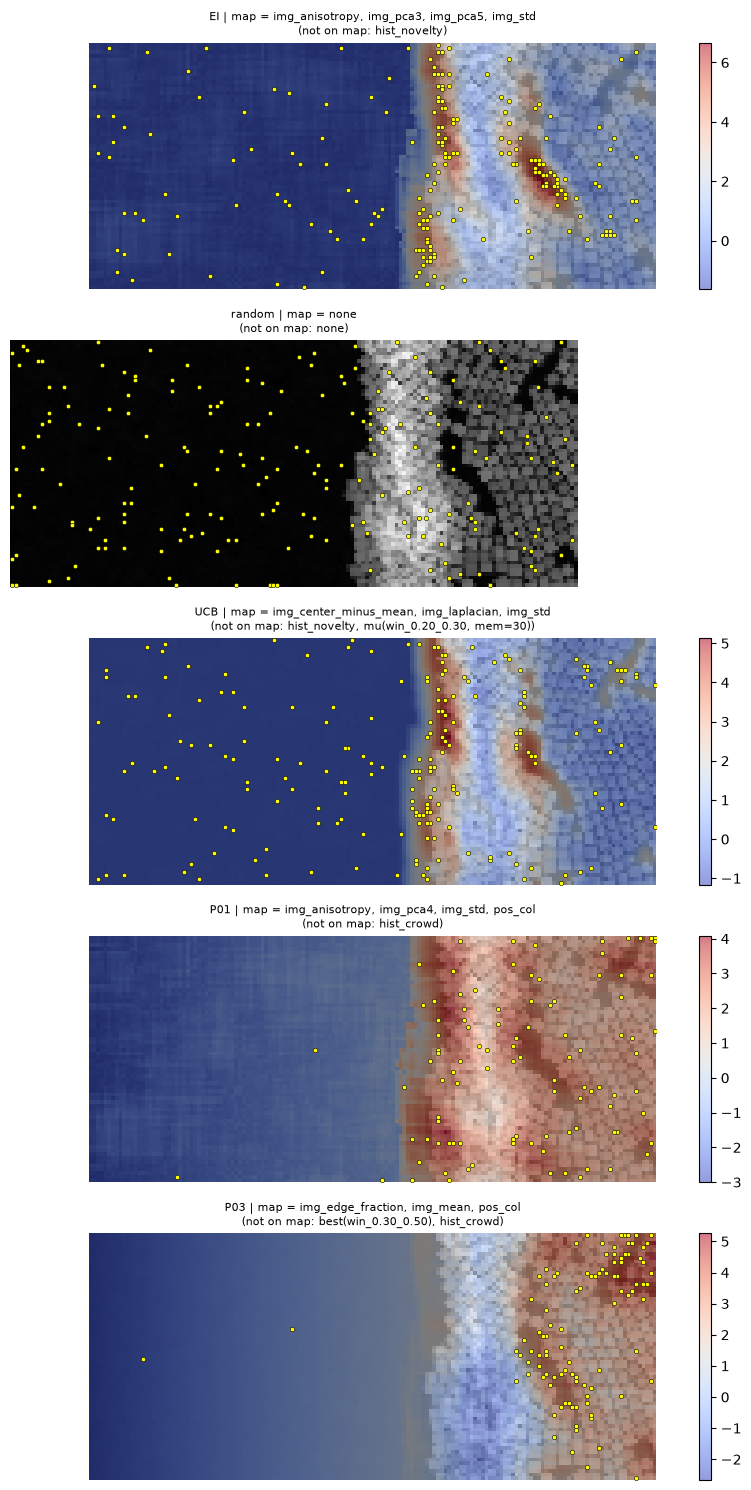

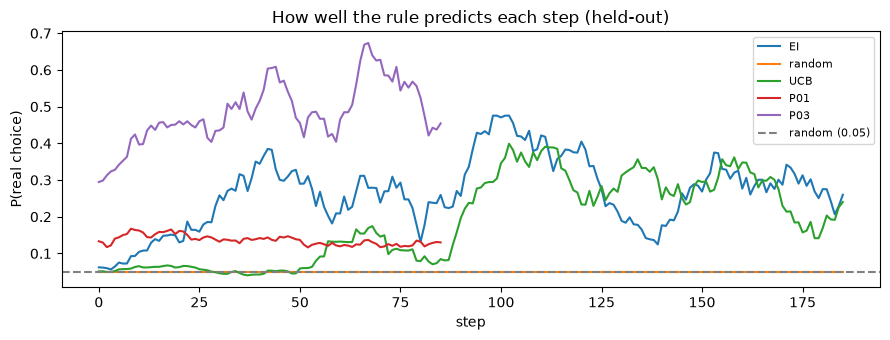


        fitness exact hit in top 3  mean P(real choice)                               weight by family spectra used? (9B)
agent                                                                                                                    
EI        0.268       42%      61%                0.259                         image 64%, history 36%                YES
random    0.000      100%     100%                0.050                                              -                 no
UCB       0.173       32%      46%                0.187                 image 59%, history 31%, mu 10%                 no
P01       0.237       24%      48%                0.135           image 55%, position 35%, history 11%                 no
P03       0.590       66%      93%                0.465  image 50%, position 26%, history 19%, best 5%                 no


In [33]:
# ============================================================
# STEP 10 — READ THE RESULTS
# ============================================================
# For every agent:
#   1. take its final explanation: the best genome over all GA runs (step 8 + 9A);
#      if even the best is at the noise level, the answer is "no rule found"
#   2. list the items with their weights, family, and the terms each item "stands for" (step 4)
#   3. honest prediction quality on held-out steps: exact hit, in top 3
#   4. a map over the image of the part of the rule that depends only on the location
#   5. how well the rule fits over time (does the agent change strategy?)
#   6. one summary table for all agents

NO_RULE_LEVEL = 0.01      # fitness below this = indistinguishable from random (step 7, test B)
spectra_used = {r["trace"]: r["spectra used?"] for r in rows}    # from step 9B


# --- 1. final explanation per agent ---
final = {}
for tid in banks:
    candidates = [(results[tid]["hall"]["fitness"].iloc[0], results[tid]["hall"]["genome"].iloc[0])]
    candidates += stability.get(tid, [])                         # the runs from step 9A
    best_fit, best_genome = max(candidates, key=lambda c: c[0])
    final[tid] = [] if best_fit < NO_RULE_LEVEL else [str(x) for x in best_genome]


# --- helper: probabilities predicted for steps the fit did NOT see (same 5 time blocks as fitness) ---
def heldout_probabilities(genome, bank):
    idx = [bank["index"][n] for n in genome]
    X = bank["X"][:, :, idx].astype(np.float64)
    winners = bank["winner"]
    P = np.zeros((len(winners), N_CAND))
    for test in np.array_split(np.arange(len(winners)), N_FOLDS):
        train = np.setdiff1d(np.arange(len(winners)), test)
        w = fit_weights(X[train], winners[train])
        P[test] = np.exp(log_probs(X[test], w))
    return P


# --- helper: which other terms an item stands for (from step 4) ---
def describe_item(name):
    for group in ["image", "position"]:
        if stands_for.get(group, {}).get(name):
            return "also = " + ", ".join(d.split(" ")[0] for d in stands_for[group][name])
    for gname, dups in stands_for["spectral"].items():          # spectral items: look at their reward g
        if dups and (f"({gname}," in name or f"({gname})" in name):
            return "reward also = " + ", ".join(d.split(" ")[0] for d in dups)
    return ""


# --- 2 + 3. items, weights and prediction quality ---
summary = []
for tid, genome in final.items():
    bank = banks[tid]
    winners = bank["winner"]
    P = heldout_probabilities(genome, bank)
    bank["P_heldout"] = P
    p_real = P[np.arange(len(winners)), winners]                  # probability given to the real choice
    rank_of_real = (P > p_real[:, None]).sum(1)                   # 0 = the real choice had the highest probability

    d = fitness(genome, bank, return_details=True)
    print(f"\n=== {short[tid]}: fitness {d['fitness']:.3f} ===")
    if not genome:
        print("   no rule found (choices look random)")
    for n, w in sorted(d["weights"].items(), key=lambda kv: -abs(kv[1])):
        print(f"   {w:+.2f}  {n:32s} [{ITEM_FAMILY[n]}]  {describe_item(n)}")

    # how much of the rule comes from each family (share of the absolute weights)
    fam = pd.Series(dtype=float)
    for n, w in d["weights"].items():
        fam[ITEM_FAMILY[n]] = fam.get(ITEM_FAMILY[n], 0) + abs(w)
    fam_text = ", ".join(f"{f} {s:.0%}" for f, s in (fam / fam.sum()).sort_values(ascending=False).items()) if len(fam) else "-"

    summary.append({"agent": short[tid],
                    "fitness": round(d["fitness"], 3),
                    "exact hit": f"{np.mean(rank_of_real == 0):.0%}",      # random = 5%
                    "in top 3": f"{np.mean(rank_of_real < 3):.0%}",        # random = 15%
                    "mean P(real choice)": round(p_real.mean(), 3),        # random = 0.05
                    "weight by family": fam_text,
                    "spectra used? (9B)": spectra_used.get(short[tid], "?")})


# --- 4. maps: the part of the rule that depends only on the LOCATION ---
# Image and position items have a value at every pixel, so we can paint
#   score(pixel) = sum of weight x (standardized item value at that pixel).
# History and spectral items depend on what was measured before, so they
# change from step to step and cannot be one map; they are listed in the title.
STATIC = {"image": clean_z["image"], "position": clean_z["position"]}

fig, axes = plt.subplots(len(final), 1, figsize=(9, 3.0 * len(final)))
for ax, (tid, genome) in zip(axes, final.items()):
    weights = fitness(genome, banks[tid], return_details=True)["weights"]
    score_map = np.zeros(H * W)
    on_map = []
    for n, w in weights.items():
        if ITEM_FAMILY[n] in STATIC:
            score_map += w * STATIC[ITEM_FAMILY[n]][n].values
            on_map.append(n)

    ax.imshow(image, cmap="gray")
    if on_map:
        im = ax.imshow(score_map.reshape(H, W), cmap="coolwarm", alpha=0.55)   # red = the agent likes it
        plt.colorbar(im, ax=ax, fraction=0.02)
    picks = [int(d["selected_index"]) for d in traces[tid]["decisions"]]
    ax.scatter(col_of[picks], row_of[picks], s=10, c="yellow", edgecolors="black", linewidths=0.4)
    not_on_map = [n for n in weights if ITEM_FAMILY[n] not in STATIC]
    ax.set_title(f"{short[tid]} | map = {', '.join(on_map) or 'none'}\n"
                 f"(not on map: {', '.join(not_on_map) or 'none'})", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()


# --- 5. fit over time: does the rule work equally well early and late? ---
fig, ax = plt.subplots(figsize=(9, 3.5))
for tid in final:
    w = banks[tid]["winner"]
    p_real = banks[tid]["P_heldout"][np.arange(len(w)), w]
    ax.plot(np.convolve(p_real, np.ones(15) / 15, mode="valid"), label=short[tid])   # 15-step moving average
ax.axhline(1 / N_CAND, color="gray", ls="--", label="random (0.05)")
ax.set_xlabel("step")
ax.set_ylabel("P(real choice)")
ax.set_title("How well the rule predicts each step (held-out)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


# --- 6. summary table ---
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 80)
print("\n" + pd.DataFrame(summary).set_index("agent").to_string())

## <font color="purple">**2.**</font> Explore the Spectra

Before clustering, always look at the data.

The structural image tells us **where** each spectrum was measured.  
The spectra tell us **what the local EELS response looks like**.

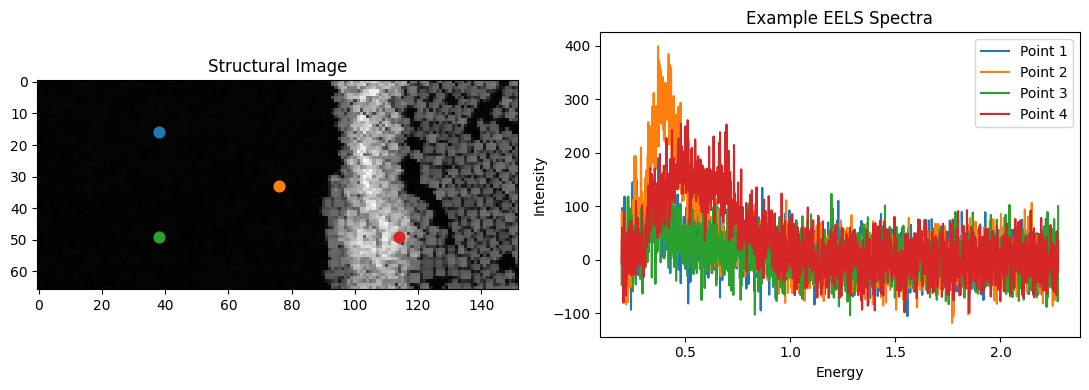

In [ ]:
# Pick a few example locations
positions = [
    (H // 4, W // 4),
    (H // 2, W // 2),
    (3 * H // 4, W // 4),
    (3 * H // 4, 3 * W // 4),
]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].imshow(image, cmap="gray")
ax[0].set_title("Structural Image")

for i, (y, x) in enumerate(positions):
    ax[0].scatter(x, y, s=60)
    ax[1].plot(energy, spectra[y, x], label=f"Point {i + 1}")

ax[1].set_title("Example EELS Spectra")
ax[1].set_xlabel("Energy")
ax[1].set_ylabel("Intensity")
ax[1].legend()

plt.tight_layout()
plt.show()

Traces

In [ ]:
trace_files = [
    "/content/day_22/eels_ei_trace.pkl",
    "/content/day_22/eels_random_trace.pkl",
    "/content/day_22/eels_ucb_trace.pkl",
    "/content/day_22/trace_P01_eels_.pkl",
    "/content/day_22/trace_P03_eels.pkl"
]

traces = {}

for i, fname in enumerate(trace_files):
    with open(fname, "rb") as f:
        traces[i] = pickle.load(f)

    print(f"Trace {i}: {fname.split('/')[-1]}")

Trace 0: eels_ei_trace.pkl
Trace 1: eels_random_trace.pkl
Trace 2: eels_ucb_trace.pkl
Trace 3: trace_P01_eels_.pkl
Trace 4: trace_P03_eels.pkl


Understanding the EELS Decision Traces
Each trace contains a sequence of decisions made by an agent while exploring an EELS dataset.

At each decision step, the agent is presented with several possible measurement locations and selects one.

For every step, the recorded information may include:
- candidate_positions — spatial coordinates of all available measurement locations.
- selected_position — index of the candidate selected by the agent.
- selected_spectrum — EELS spectrum measured at the selected location.
- selected_axis — corresponding energy-loss axis (eV).
- step — decision step number.
The four traces represent different decision-making strategies: Expected Improvement (EI), Random Sampling, Upper Confidence Bound (UCB), and PO6.

In [ ]:
TRACE_ID = 4
STEP = 1

trace = traces[TRACE_ID]
step_data = trace["decisions"][STEP - 1]

print("Step:", step_data["step"])

print("Selected candidate position:", step_data["selected_position"])
print("Selected dataset index:", step_data["selected_index"])
print("Selected coordinates:", step_data["selected_coordinates"])

print("Number of candidates:", len(step_data["candidate_indices"]))
print("Candidate indices:", step_data["candidate_indices"])
print("Candidate coordinates:", step_data["candidate_coordinates"])

# print("Selected reward:", step_data["selected_reward"])

print("Selected spectrum shape:", np.shape(step_data["selected_spectrum"]))
print("Energy axis shape:", np.shape(step_data["selected_axis"]))

Step: 1
Selected candidate position: 10
Selected dataset index: 3926
Selected coordinates: [ 25 126]
Number of candidates: 20
Candidate indices: [ 844 7959 7939 3644 6871 2156 2717 5571 6716 9399 3926 6660 3532  642
 3058 1992 1662 7401 3327 5374]
Candidate coordinates: [[  5  84]
 [ 52  55]
 [ 52  35]
 [ 23 148]
 [ 45  31]
 [ 14  28]
 [ 17 133]
 [ 36  99]
 [ 44  28]
 [ 61 127]
 [ 25 126]
 [ 43 124]
 [ 23  36]
 [  4  34]
 [ 20  18]
 [ 13  16]
 [ 10 142]
 [ 48 105]
 [ 21 135]
 [ 35  54]]
Selected spectrum shape: (4198,)
Energy axis shape: (4198,)


VISUALIZE ONE DECISION STEP

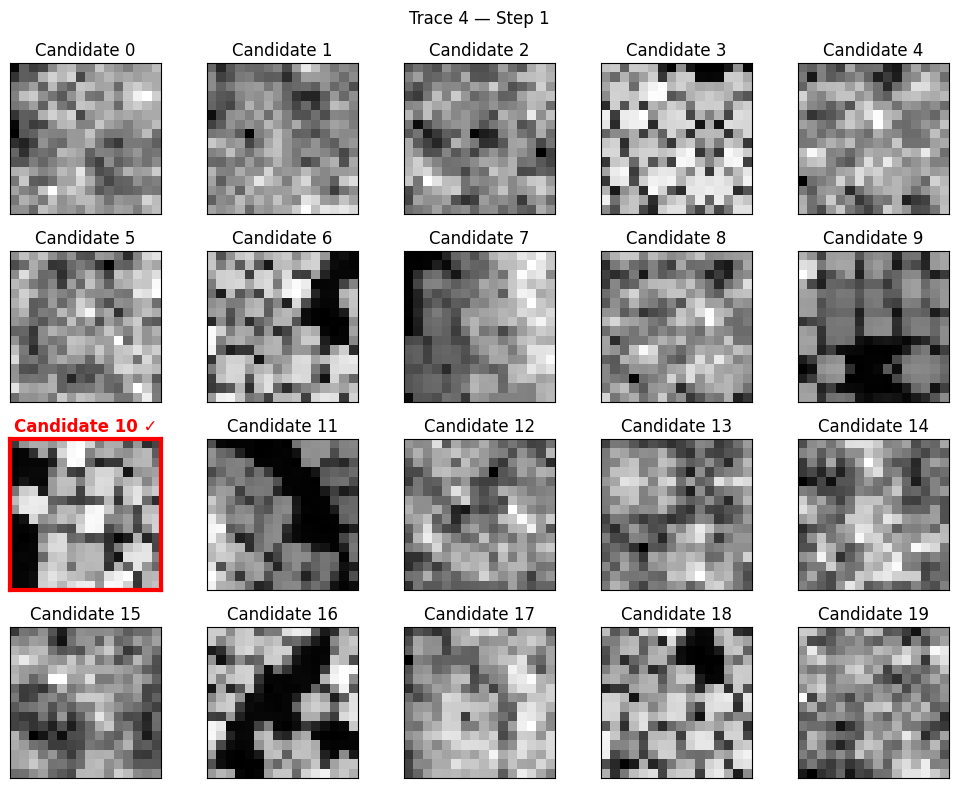

In [ ]:
patches = step_data["candidate_patches"]
selected = step_data["selected_position"]

n = len(patches)

ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(10, 2 * nrows)
)

axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):

    if i >= n:
        ax.axis("off")
        continue

    patch = np.squeeze(patches[i])   # <-- fixes (1,16,16) -> (16,16)

    ax.imshow(
        patch,
        cmap="gray"
    )

    if i == selected:

        ax.set_title(
            f"Candidate {i} ✓",
            color="red",
            weight="bold"
        )

        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(3)

    else:

        ax.set_title(
            f"Candidate {i}"
        )

    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    f"Trace {TRACE_ID} — Step {STEP}"
)

plt.tight_layout()
plt.show()

Show the spectrum

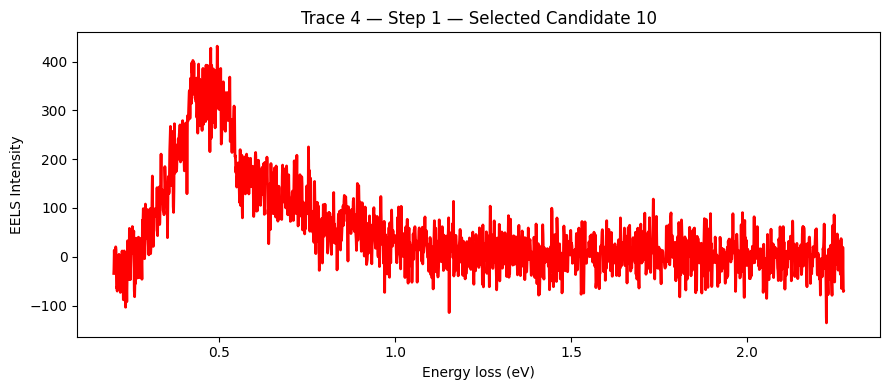

In [ ]:
energy = step_data["selected_axis"]
spectrum = step_data["selected_spectrum"]

plt.figure(figsize=(9, 4))

plt.plot(energy, spectrum, color="red", linewidth=2)

plt.xlabel("Energy loss (eV)")
plt.ylabel("EELS Intensity")
plt.title(f"Trace {TRACE_ID} — Step {STEP} — Selected Candidate {selected}")

plt.tight_layout()
plt.show()

TRACE MAP ON ORIGINAL IMAGE

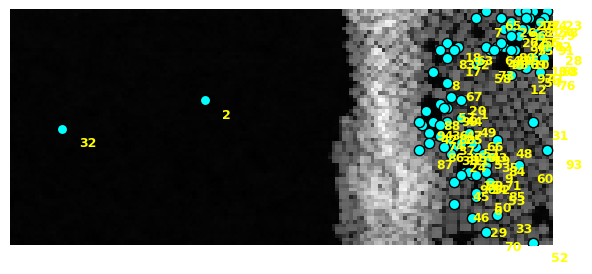

In [ ]:
trace = traces[TRACE_ID]
decisions = trace["decisions"]

xs = [d["selected_coordinates"][1] for d in decisions]
ys = [d["selected_coordinates"][0] for d in decisions]

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(image, cmap="gray")

ax.scatter(
    xs, ys,
    s=55,
    color="cyan",
    edgecolors="black"
)

for i, (x, y) in enumerate(zip(xs, ys)):
    ax.text(
        x + 5,
        y + 5,
        str(decisions[i]["step"]),
        fontsize=9,
        color="yellow",
        weight="bold"
    )

ax.axis("off")
plt.show()

DECISION MAPS FOR 10 TRACES


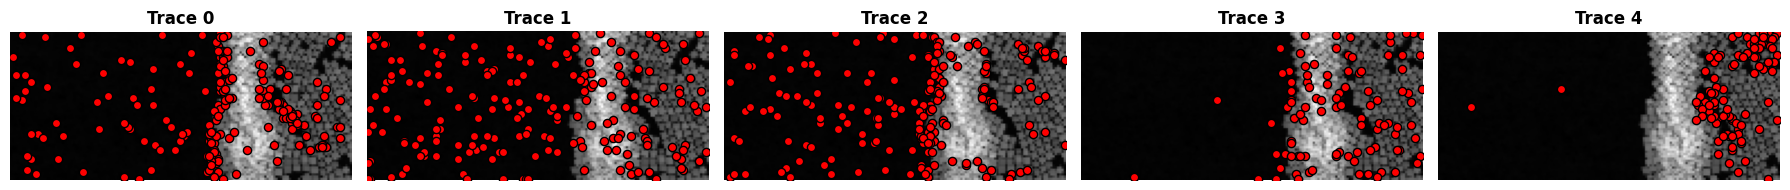

In [ ]:
TRACE_IDS = list(traces.keys())

ncols = 5
nrows = int(np.ceil(len(TRACE_IDS) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(18, 5 * nrows)
)

axes = np.array(axes).flatten()

for ax, trace_id in zip(axes, TRACE_IDS):

    trace = traces[trace_id]
    decisions = trace["decisions"]

    xs = [d["selected_coordinates"][1] for d in decisions]
    ys = [d["selected_coordinates"][0] for d in decisions]

    # Original EELS image
    ax.imshow(image, cmap="gray")

    # Selected locations
    ax.scatter(
        xs,
        ys,
        s=35,
        color="red",
        edgecolors="black"
    )

    ax.set_title(
        f"Trace {trace_id}",
        fontsize=12,
        weight="bold"
    )

    ax.axis("off")

# Hide unused axes
for ax in axes[len(TRACE_IDS):]:
    ax.axis("off")

plt.tight_layout()
plt.show()